### Dataset Access and Archive Verification

The Substation Equipment Semantic Segmentation Dataset is stored as a ZIP archive in Google Drive. The initial step establishes access to the dataset and verifies the archive's location, size, and readability.
The Dataset extraction and validation will be performed in subsequent steps after confirming the archive structure.

In [1]:

from google.colab import drive
from pathlib import Path
from zipfile import ZipFile, BadZipFile
dataset_archive_name = "substation-semantic-dataset.zip"
google_drive_root = Path("/content/drive/MyDrive")
try:
    # Connect Colab to Google Drive.
    drive.mount("/content/drive")
    if not google_drive_root.is_dir():
        raise FileNotFoundError("Google Drive MyDrive folder is unavailable.")
    # Locate the uploaded archive nad its folder structure
    matching_archives = [
        archive_path
        for archive_path in google_drive_root.rglob(dataset_archive_name)
        if archive_path.is_file()
    ]
    if not matching_archives:
        print(f"Dataset archive not found: {dataset_archive_name}")
    elif len(matching_archives) > 1:
        print("Multiple matching archives found. Select the correct path:")
        for archive_path in matching_archives:
            print(f" - {archive_path}")
    else:
        dataset_archive_path = matching_archives[0]
        with ZipFile(dataset_archive_path, "r") as dataset_archive:
            archive_entries = dataset_archive.infolist()
            archived_files = [
                entry for entry in archive_entries if not entry.is_dir()
            ]
        print("Dataset archive located successfully.")
        print(f"Archive path: {dataset_archive_path}")
        print(f"Archive size: {dataset_archive_path.stat().st_size / (1024 ** 3):.3f} GB")
        print(f"Total archive entries: {len(archive_entries)}")
        print(f"Total archived files: {len(archived_files)}")
        print("ZIP structure is readable. Extraction has not started.")
except (BadZipFile, OSError) as error:
    print(f"Archive access error: {type(error).__name__}: {error}")
except Exception as error:
    print(f"Setup error: {type(error).__name__}: {error}")

Mounted at /content/drive
Dataset archive located successfully.
Archive path: /content/drive/MyDrive/substation-semantic-dataset.zip
Archive size: 1.718 GB
Total archive entries: 8307
Total archived files: 8302
ZIP structure is readable. Extraction has not started.


### 2. Dataset Archive Structure Inspection

Before extracting the dataset, we examine the dataset archive to identify its internal directory structure, file formats, and distribution of files across directories.
This inspection helps establish how the original images, polygon annotations, and segmentation masks are organized. It also provides an initial inventory for subsequent dataset integrity checks.


In [2]:
from collections import Counter
from pathlib import PurePosixPath
from zipfile import ZipFile, BadZipFile
try:
    # Use the archive path verified in the previous cell code
    with ZipFile(dataset_archive_path, "r") as dataset_archive:
        archive_entries = dataset_archive.infolist()
        archived_file_paths = [
            PurePosixPath(entry.filename)
            for entry in archive_entries
            if not entry.is_dir()
        ]
        # Identify the top level directories and files.
        top_level_items = sorted({
            file_path.parts[0]
            for file_path in archived_file_paths
        })
        # Count files by extension to understand the dataset contents.
        file_extension_counts = Counter(
            file_path.suffix.lower() or "[no extension]"
            for file_path in archived_file_paths
        )
        # Count files within each top level directory.
        top_level_file_counts = Counter(
            file_path.parts[0]
            for file_path in archived_file_paths
        )
        print("Dataset Archive Structure")
        print("\nTop level items:")
        for item_name in top_level_items:
            print(f" {item_name}")
        print("\nFile counts by top level location:")
        for item_name, file_count in sorted(top_level_file_counts.items()):
            print(f"  {item_name}: {file_count:,}")
        print("\nFile counts by extension:")
        for extension, file_count in sorted(file_extension_counts.items()):
            print(f"  {extension}: {file_count:,}")
        print("\nSample archive paths:")
        for file_path in archived_file_paths[:15]:
            print(f"{file_path}")
        print("\nInspection completed.")
except (BadZipFile, OSError) as error:
    print(f"Archive inspection failed: {type(error).__name__}: {error}")
except Exception as error:
    print(f"Unexpected inspection error: {type(error).__name__}: {error}")


Dataset Archive Structure

Top level items:
 14_masks
 15_masks
 classes.txt
 images
 json2png.py
 labels_json
 porcelain_masks

File counts by top level location:
  14_masks: 1,660
  15_masks: 1,660
  classes.txt: 1
  images: 1,660
  json2png.py: 1
  labels_json: 1,660
  porcelain_masks: 1,660

File counts by extension:
  .jpeg: 29
  .jpg: 1,631
  .json: 1,660
  .png: 4,980
  .py: 1
  .txt: 1

Sample archive paths:
14_masks/1PANO0001.png
14_masks/202107131404432209708.png
14_masks/202107131406516153763.png
14_masks/202107131414223898673.png
14_masks/202107131415546185208.png
14_masks/202107131417399836310.png
14_masks/202107131418280517276.png
14_masks/202107131429105929021.png
14_masks/202107131435376255774.png
14_masks/202107131440078201999.png
14_masks/202107131445542657117.png
14_masks/20210713_144031.png
14_masks/20210713_144034.png
14_masks/20210713_144039.png
14_masks/20210713_144106.png

Inspection completed.


### Dataset Integrity Verification and Extraction

We check the dataset archive for compressed file integrity and safely extract it to the Google Colab runtime.
This extraction process verifies archive paths, checks available disk space, and preserves the original dataset stored in Google Drive.
Using Colab's local storage allows us to handle subsequent image annotation and segmentation mask analysis without repeatedly accessing idividual files through google drive


In [3]:
from pathlib import Path, PurePosixPath
from zipfile import ZipFile, BadZipFile
import shutil
dataset_extraction_directory = Path(
    "/content/substation_semantic_dataset"
)
try:
    #Ensure the availability of the source archive
    if not dataset_archive_path.is_file():
        raise FileNotFoundError(
            f"Dataset archive not found: {dataset_archive_path}"
        )
    #Avoid mixing a new extraction with files from an earlier run.
    if dataset_extraction_directory.exists():
        raise FileExistsError(
            f"Extraction directory already exists: "
            f"{dataset_extraction_directory}. "
            "Inspect it before attempting extraction again."
        )
    with ZipFile(dataset_archive_path, "r") as dataset_archive:
        archive_entries = dataset_archive.infolist()
        # Reject unsafe paths before writing any extracted files.
        for archive_entry in archive_entries:
            entry_path = PurePosixPath(archive_entry.filename)
            if (
                entry_path.is_absolute()
                or ".." in entry_path.parts
                or "\\" in archive_entry.filename
            ):
                raise ValueError(
                    f"Unsafe archive path detected: {archive_entry.filename}"
                )
        # Verify compressed file integrity before extraction.
        print("Checking zip integrity.")
        corrupted_file = dataset_archive.testzip()
        if corrupted_file is not None:
            raise BadZipFile(
                f"Integrity check failed: {corrupted_file}"
            )
        # Check whether Colab has sufficient free disk space.
        required_bytes = sum(
            entry.file_size
            for entry in archive_entries
            if not entry.is_dir()
        )
        available_bytes = shutil.disk_usage("/content").free
        print(f"Uncompressed dataset size: {required_bytes / (1024**3):.2f} GB")
        print(f"Available disk space: {available_bytes / (1024**3):.2f} GB")
        if required_bytes > available_bytes:
            raise OSError(
                "Insufficient disk space for dataset extraction."
            )
        print("\nExtracting dataset.")
        dataset_extraction_directory.mkdir(
            parents=True,
            exist_ok=False
        )
        dataset_archive.extractall(dataset_extraction_directory)
    print("\nDataset extraction completed successfully.")
    print(f"Extraction directory: {dataset_extraction_directory}")
    print("\nExtracted top level contents:")
    for extracted_item in sorted(
        dataset_extraction_directory.iterdir()
    ):
        print(f"  {extracted_item.name}")
except (FileNotFoundError, FileExistsError, BadZipFile,
        ValueError, OSError) as error:
    print(f"Dataset extraction error: {type(error).__name__}: {error}")
except Exception as error:
    print(f"Unexpected error: {type(error).__name__}: {error}")

Checking zip integrity.
Uncompressed dataset size: 2.01 GB
Available disk space: 110.81 GB

Extracting dataset.

Dataset extraction completed successfully.
Extraction directory: /content/substation_semantic_dataset

Extracted top level contents:
  14_masks
  15_masks
  classes.txt
  images
  json2png.py
  labels_json
  porcelain_masks


### Dataset File Correspondence and Completeness Validation

Before analyzing image characteristics and annotation distributions we examine the extracted dataset for file level consistency.

We match each original image with its corresponding JSON annotation and segementation masks using the filename identifier.

This validation also checks for duplicate identifiers, missing files, additional files, and unexpected file extensions.

This step establishes whether the dataset files can be reliably paired for subsequent image analysis, segmentation mask inspection, and annotation validation.

Note: File correspondence alone does not establish annotation correctness or image integrity. These properties will be investigated separately during the exploratory analysis.

In [4]:
from pathlib import Path
from collections import Counter
dataset_directories = {
    "Images": dataset_extraction_directory / "images",
    "JSON Annotations": dataset_extraction_directory / "labels_json",
    "15_Class Masks": dataset_extraction_directory / "15_masks",
    "14_Class Masks": dataset_extraction_directory / "14_masks",
    "Porcelain Masks": dataset_extraction_directory / "porcelain_masks"
}
expected_file_extensions = {
    "Images": {".jpg", ".jpeg"},
    "JSON Annotations": {".json"},
    "15_Class Masks": {".png"},
    "14_Class Masks": {".png"},
    "Porcelain Masks": {".png"}
}
try:
    dataset_file_inventory = {}
    # Collect the files from each directory without altering the dataset.
    for directory_name, directory_path in dataset_directories.items():
        if not directory_path.is_dir():
            raise FileNotFoundError(
                f"Required directory is missing: {directory_path}"
            )
        directory_files = sorted(
            file_path
            for file_path in directory_path.iterdir()
            if file_path.is_file()
        )
        dataset_file_inventory[directory_name] = directory_files
    # Use filename stems to match images with their annotations and masks.
    image_identifiers = {
        file_path.stem
        for file_path in dataset_file_inventory["Images"]
    }
    print("Dataset File Validation")
    dataset_validation_results = {}
    for directory_name, directory_files in dataset_file_inventory.items():
        file_identifiers = [
            file_path.stem for file_path in directory_files
        ]
        identifier_counts = Counter(file_identifiers)
        duplicate_identifiers = sorted(
            identifier
            for identifier, count in identifier_counts.items()
            if count > 1
        )
        missing_identifiers = sorted(
            image_identifiers - set(file_identifiers)
        )
        additional_identifiers = sorted(
            set(file_identifiers) - image_identifiers
        )
        unexpected_extensions = sorted(
            {
                file_path.suffix.lower()
                for file_path in directory_files
                if file_path.suffix.lower()
                not in expected_file_extensions[directory_name]
            }
        )
        dataset_validation_results[directory_name] = {
            "file_count": len(directory_files),
            "unique_identifiers": len(identifier_counts),
            "duplicate_identifiers": duplicate_identifiers,
            "missing_identifiers": missing_identifiers,
            "additional_identifiers": additional_identifiers,
            "unexpected_extensions": unexpected_extensions
        }
        print(f"\n{directory_name}")
        print(f"Total files: {len(directory_files):,}")
        print(f"Unique identifiers: {len(identifier_counts):,}")
        print(f"Duplicate identifiers: {len(duplicate_identifiers)}")
        print(f"Missing image identifiers: {len(missing_identifiers)}")
        print(f"Additional identifiers: {len(additional_identifiers)}")
        print(f"Unexpected extensions: {unexpected_extensions}")
        if duplicate_identifiers:
            print(f"Duplicate examples: {duplicate_identifiers[:5]}")
        if missing_identifiers:
            print(f"Missing examples: {missing_identifiers[:5]}")
        if additional_identifiers:
            print(f"Additional examples: {additional_identifiers[:5]}")
    # Summarize whether all the five directories have matching identifiers.
    dataset_files_aligned = all(
        not validation_result["duplicate_identifiers"]
        and not validation_result["missing_identifiers"]
        and not validation_result["additional_identifiers"]
        and not validation_result["unexpected_extensions"]
        for validation_result in dataset_validation_results.values()
    )
    print("Final File Correspondence Status")
    if dataset_files_aligned:
        print("Pass: All five directories have matching file identifiers.")
    else:
        print("Review Required: File correspondence issues were detected.")
    print(
        "\nNote: This check validates filenames and extensions, "
        "not image readability or annotation correctness."
    )
except (FileNotFoundError, PermissionError, OSError) as error:
    print(f"Dataset validation error: {type(error).__name__}: {error}")
except Exception as error:
    print(f"Unexpected validation error: {type(error).__name__}: {error}")

Dataset File Validation

Images
Total files: 1,660
Unique identifiers: 1,660
Duplicate identifiers: 0
Missing image identifiers: 0
Additional identifiers: 0
Unexpected extensions: []

JSON Annotations
Total files: 1,660
Unique identifiers: 1,660
Duplicate identifiers: 0
Missing image identifiers: 0
Additional identifiers: 0
Unexpected extensions: []

15_Class Masks
Total files: 1,660
Unique identifiers: 1,660
Duplicate identifiers: 0
Missing image identifiers: 0
Additional identifiers: 0
Unexpected extensions: []

14_Class Masks
Total files: 1,660
Unique identifiers: 1,660
Duplicate identifiers: 0
Missing image identifiers: 0
Additional identifiers: 0
Unexpected extensions: []

Porcelain Masks
Total files: 1,660
Unique identifiers: 1,660
Duplicate identifiers: 0
Missing image identifiers: 0
Additional identifiers: 0
Unexpected extensions: []
Final File Correspondence Status
Pass: All five directories have matching file identifiers.

Note: This check validates filenames and extensions, 

### Class Definitions and Annotation Schema Inspection
Next we examine the dataset's class definitions and JSON annotation structure before conducting class level staistical analysis

Here the original class list is inspected to establish the available semantic categories and their ordering and
a reproducible sample of JSON annotation files is then examined to identify the annotation schema, including the organization of object labels and associated metadata.

This preliminary ispections is necessary and helps us to determine how object instances, polygon coordinates and class identifiers can be extraceted for subsequent analysis

This inspection is limited to understanding the data representation. No conclusions about class frequencies, polygon validity, or annotation quality are drawn at this stage.

In [5]:
import json
from pathlib import Path
try:
    # Read the class definitions exactly as provided by the orignal dataset authors
    class_definition_path = dataset_extraction_directory / "classes.txt"
    if not class_definition_path.is_file():
        raise FileNotFoundError(
            f"Class definition file not found: {class_definition_path}"
        )
    class_definition_lines = class_definition_path.read_text(
        encoding="utf-8-sig"
    ).splitlines()
    dataset_class_names = [
        class_name.strip()
        for class_name in class_definition_lines
        if class_name.strip()
    ]
    print("Class Definitions:")
    for class_index, class_name in enumerate(dataset_class_names):
        print(f"{class_index:>2}: {class_name}")
    print(f"\nTotal non empty class entries:{len(dataset_class_names)}")
    print(f"Unique class names:{len(set(dataset_class_names))}")
    # Inspecting a small, reproducible sample of annotation files.
    annotation_directory = dataset_extraction_directory / "labels_json"
    annotation_files = sorted(annotation_directory.glob("*.json"))
    if not annotation_files:
        raise FileNotFoundError(
            "No JSON annotation files were found."
        )
    selected_annotation_files = annotation_files[:3]
    print("\nJSON Annotation Structure")
    for annotation_path in selected_annotation_files:
        print(f"\nFile:{annotation_path.name}")
        with annotation_path.open("r", encoding="utf-8-sig") as annotation_file:
            annotation_content = json.load(annotation_file)
        print(f"Root data type: {type(annotation_content).__name__}")
        if isinstance(annotation_content, dict):
            print("Top level keys:")
            for annotation_key in annotation_content:
                print(f"  {annotation_key}")
            # Examine the structure without printing large coordinate arrays.
            for annotation_key, annotation_value in annotation_content.items():
                if isinstance(annotation_value, list):
                    print(
                        f"  {annotation_key}: list with "
                        f"{len(annotation_value)} entries"
                    )
                    if annotation_value:
                        first_entry = annotation_value[0]
                        print(
                            f"First entry type: "
                            f"{type(first_entry).__name__}"
                        )
                        if isinstance(first_entry, dict):
                            print(
                                f"First entry keys: "
                                f"{list(first_entry.keys())}"
                            )
                elif isinstance(annotation_value, dict):
                    print(
                        f"  {annotation_key}: dictionary with "
                        f"{len(annotation_value)} keys"
                    )
                else:
                    print(
                        f"  {annotation_key}: "
                        f"{type(annotation_value).__name__}"
                    )
        elif isinstance(annotation_content, list):
            print(f"Number of root entries: {len(annotation_content)}")
            if annotation_content:
                first_entry = annotation_content[0]
                print(f"First entry type: {type(first_entry).__name__}")
                if isinstance(first_entry, dict):
                    print(f"First entry keys: {list(first_entry.keys())}")
    print("\nSchema inspection completed without modifying dataset files.")
except (FileNotFoundError, PermissionError, OSError) as error:
    print(f"File access error: {type(error).__name__}: {error}")
except (json.JSONDecodeError, UnicodeError) as error:
    print(f"Annotation parsing error: {type(error).__name__}: {error}")
except Exception as error:
    print(f"Unexpected inspection error: {type(error).__name__}: {error}")

Class Definitions:
 0: Background
 1: Open blade disconnect switch
 2: Closed blade disconnect switch
 3: Open tandem disconnect switch
 4: Closed tandem disconnect switch
 5: Breaker
 6: Fuse disconnect switch
 7: Glass disc insulator
 8: Porcelain pin insulator
 9: Muffle
10: Lightning arrester
11: Recloser
12: Power transformer
13: Current transformer
14: Potential transformer
15: Tripolar disconnect switch

Total non empty class entries:16
Unique class names:16

JSON Annotation Structure

File:1PANO0001.json
Root data type: dict
Top level keys:
  version
  flags
  shapes
  imagePath
  imageData
  imageHeight
  imageWidth
  version: str
  flags: dictionary with 1 keys
  shapes: list with 122 entries
First entry type: dict
First entry keys: ['label', 'points', 'group_id', 'shape_type', 'flags']
  imagePath: str
  imageData: NoneType
  imageHeight: int
  imageWidth: int

File:202107131404432209708.json
Root data type: dict
Top level keys:
  version
  imagePath
  imageHeight
  imageWid

### Class Definitions and JSON Annotation Structure

The `classes.txt` file contains 16 class names, including the background class and 15 electrical substation equipment classes. Each class has a unique name, and the ordering of the classes has been recorded for further analysis.

The JSON annotation files follow a LabelMe style structure. Each file contains image information, including its height and width, along with a `shapes` field that stores the object annotations. Each inspected shape includes a class label (`label`), coordinate points (`points`), a group identifier (`group_id`), a shape type (`shape_type`), and additional flags (`flags`).

Three annotation files were inspected to understand their structure. They contained 122, 4, and 14 annotated shapes, respectively. This shows that the number of annotations varies across the sampled images.

The image dimensions recorded in the JSON files can be used later to check whether annotation coordinates fall within the image boundaries.

**Observation:** The initial inspection confirms the class definitions and provides an understanding of how annotations are organized. However, only three JSON files were examined. The remaining annotation files still need to be validated to identify possible inconsistencies in labels, coordinates, and shape types before proceeding with the detailed EDA.

### Annotation Integrity and Equipment Class Distribution

We now examine all JSON annotation files to assess annotation consistency and the distribution of equipment categories

This analysis extracts equipment labels, object counts, shape types, polygon point counts, and image dimensions. It also checks for missing labels, unexpected class names, invalid coordinate structures, insufficient polygon vertices, and coordinates outside the annotated image boundaries.

Validation issues are recorded separately so that individual annotation problems do not prevent inspection of the remaining dataset.

The resulting summaries provide an initial understanding of equipment representation and annotation complexity. These findings will support subsequent investigations into class imbalance, segmentation suitability, equipment state recognition, and potential modelling limitations.

In [6]:
import json
import math
from collections import Counter
from pathlib import Path
import pandas as pd
annotation_directory = dataset_extraction_directory / "labels_json"
annotation_summary_records = []
object_annotation_records = []
annotation_validation_issues = []
valid_equipment_labels = set(dataset_class_names[1:])
annotation_files = sorted(annotation_directory.glob("*.json"))
for annotation_path in annotation_files:
    try:
        with annotation_path.open("r", encoding="utf-8-sig") as annotation_file:
            annotation_data = json.load(annotation_file)
        if not isinstance(annotation_data, dict):
            raise ValueError("Annotation root must be a dictionary.")
        image_height = annotation_data.get("imageHeight")
        image_width = annotation_data.get("imageWidth")
        annotated_shapes = annotation_data.get("shapes")
        if not isinstance(annotated_shapes, list):
            raise ValueError("The shapes field is missing or is not a list.")
        valid_image_dimensions = (
            isinstance(image_height, int)
            and not isinstance(image_height, bool)
            and image_height > 0
            and isinstance(image_width, int)
            and not isinstance(image_width, bool)
            and image_width > 0
        )
        if not valid_image_dimensions:
            annotation_validation_issues.append({
                "file": annotation_path.name,
                "shape_index": None,
                "issue": "Missing or invalid image dimensions"
            })
        annotation_summary_records.append({
            "image_identifier": annotation_path.stem,
            "annotation_file": annotation_path.name,
            "image_width": image_width,
            "image_height": image_height,
            "annotated_object_count": len(annotated_shapes)
        })
        for shape_index, shape_data in enumerate(annotated_shapes):
            if not isinstance(shape_data, dict):
                annotation_validation_issues.append({
                    "file": annotation_path.name,
                    "shape_index": shape_index,
                    "issue": "Shape entry is not a dictionary"
                })
                continue
            equipment_label = shape_data.get("label")
            shape_type = shape_data.get("shape_type")
            polygon_points = shape_data.get("points")
            if not isinstance(equipment_label, str) or not equipment_label.strip():
                annotation_validation_issues.append({
                    "file": annotation_path.name,
                    "shape_index": shape_index,
                    "issue": "Missing or invalid equipment label"
                })
            elif equipment_label not in valid_equipment_labels:
                annotation_validation_issues.append({
                    "file": annotation_path.name,
                    "shape_index": shape_index,
                    "issue": f"Label not in equipment class definitions: {equipment_label}"
                })
            valid_point_structure = isinstance(polygon_points, list)
            if valid_point_structure:
                valid_point_structure = all(
                    isinstance(point, (list, tuple))
                    and len(point) == 2
                    and all(
                        isinstance(coordinate, (int, float))
                        and not isinstance(coordinate, bool)
                        and math.isfinite(coordinate)
                        for coordinate in point
                    )
                    for point in polygon_points
                )
            if not valid_point_structure:
                annotation_validation_issues.append({
                    "file": annotation_path.name,
                    "shape_index": shape_index,
                    "issue": "Invalid coordinate structure"
                })
            point_count = (
                len(polygon_points)
                if isinstance(polygon_points, list)
                else None
            )
            if shape_type == "polygon" and point_count is not None and point_count < 3:
                annotation_validation_issues.append({
                    "file": annotation_path.name,
                    "shape_index": shape_index,
                    "issue": "Polygon has fewer than three points"
                })
            if valid_point_structure and valid_image_dimensions:
                coordinates_outside_image = any(
                    not (0 <= point[0] <= image_width)
                    or not (0 <= point[1] <= image_height)
                    for point in polygon_points
                )
                if coordinates_outside_image:
                    annotation_validation_issues.append({
                        "file": annotation_path.name,
                        "shape_index": shape_index,
                        "issue": "Coordinates outside annotated image dimensions"
                    })
            object_annotation_records.append({
                "image_identifier": annotation_path.stem,
                "annotation_file": annotation_path.name,
                "shape_index": shape_index,
                "equipment_label": equipment_label,
                "shape_type": shape_type,
                "point_count": point_count,
                "group_id": shape_data.get("group_id")
            })
    except (OSError, UnicodeError, json.JSONDecodeError, ValueError) as error:
        annotation_validation_issues.append({
            "file": annotation_path.name,
            "shape_index": None,
            "issue": f"{type(error).__name__}: {error}"
        })
annotation_summary_df = pd.DataFrame(annotation_summary_records)
object_annotations_df = pd.DataFrame(object_annotation_records)
annotation_issues_df = pd.DataFrame(
    annotation_validation_issues,
    columns=["file", "shape_index", "issue"]
)
print("Complete Annotation Validation Summary")
print(f"JSON files discovered:{len(annotation_files):,}")
print(f"JSON files successfully parsed:{len(annotation_summary_df):,}")
print(f"Shape records collected:{len(object_annotations_df):,}")
print(f"Validation issues recorded:{len(annotation_issues_df):,}")
if not object_annotations_df.empty:
    print("\nClass Distribution")
    class_distribution_df = (
        object_annotations_df["equipment_label"]
        .value_counts(dropna=False)
        .rename_axis("equipment_class")
        .reset_index(name="object_count")
    )
    print(class_distribution_df.to_string(index=False))
    print("\nShape type distribution")
    print(
        object_annotations_df["shape_type"]
        .value_counts(dropna=False)
        .to_string()
    )
if not annotation_summary_df.empty:
    print("\nObjects per Image")
    print(
        annotation_summary_df["annotated_object_count"]
        .describe()
        .to_string()
    )
if not annotation_issues_df.empty:
    print("\nValidation Issue Summary")
    print(
        annotation_issues_df["issue"]
        .value_counts()
        .head(20)
        .to_string()
    )
    print("\nFirst 10 recorded issues:")
    print(annotation_issues_df.head(10).to_string(index=False))
else:
    print("\nNo validation issues detected by the implemented checks.")
print("\nAnnotation inspection completed.")

Complete Annotation Validation Summary
JSON files discovered:1,660
JSON files successfully parsed:1,660
Shape records collected:52,886
Validation issues recorded:2,328

Class Distribution
                equipment_class  object_count
        Porcelain pin insulator         26450
 Closed blade disconnect switch          5224
           Glass disc insulator          3180
     Tripolar disconnect switch          2348
                       Recloser          2329
                     Background          2284
            Current transformer          2128
             Lightning arrester          1974
  Open tandem disconnect switch          1596
                         Muffle          1354
                        Breaker           980
Closed tandem disconnect switch           957
              Power transformer           768
          Potential transformer           651
         Fuse disconnect switch           355
   Open blade disconnect switch           308

Shape type distribution
shape

### Annotation Validation and Equipment Class Distribution

All 1,660 JSON annotation files were successfully parsed, producing a total of 52,886 annotated shapes. Every recorded shape has its type specified as `polygon`, confirming that polygon annotations are used throughout the dataset.

The number of annotations varies considerably between images, ranging from 0 to 268, with an average of approximately 31.86 annotations per image. The median is 23, indicating that some images contain substantially more annotated objects than others.

The class distribution is highly imbalanced. Porcelain pin insulators account for 26,450 annotations, making them the most frequently represented equipment class. In comparison, open blade disconnect switches have only 308 annotations. This imbalance is an important consideration for future modelling and evaluation, particularly for less frequently represented equipment categories.

The validation process recorded 2,328 issues. Of these, 2,284 were associated with the `Background` label. Since Background is explicitly included in the dataset's class definitions, these records should not automatically be considered invalid. The remaining 44 issues involve polygon coordinates extending beyond the image dimensions specified in the annotation files.

Excluding Background annotations, the dataset contains 50,602 equipment annotations. This differs from the 50,705 objects reported in the dataset documentation by 103 annotations. The reason for this difference has not yet been established.

**Observation:** The annotation files are readable and consistently use polygon shapes, but the analysis has identified substantial class imbalance, a difference between observed and documented object counts, and a small number of out of bounds coordinate annotations. These findings require further investigation before finalizing the dataset preparation and modelling strategy.

### Investigation of Annotation Discrepancies

The initial annotation validation identified differences between the observed equipment counts and the values reported in the dataset documentation. It also identified Background polygons and annotations containing coordinates outside the recorded image boundaries.

This stage investigates these findings in detail.

The observed equipment counts are compared with the published class frequencies to identify which categories contribute to the difference. Images containing no annotated shapes are identified separately.

Background annotations are examined to understand their frequency, distribution across images, and polygon structure.

For polygons with out of bounds coordinates, the analysis measures the number of affected points and the maximum horizontal and vertical deviations from the recorded image boundaries.

These checks are intended to distinguish possible annotation inconsistencies from differences in dataset representation. No annotations are corrected, removed, or modified during this investigation.

In [7]:
import json
import math
from collections import Counter
import pandas as pd
try:
    required_dataframes = {
        "annotation_summary_df": annotation_summary_df,
        "object_annotations_df": object_annotations_df,
        "annotation_issues_df": annotation_issues_df
    }
    for dataframe_name, dataframe_value in required_dataframes.items():
        if not isinstance(dataframe_value, pd.DataFrame):
            raise TypeError(f"{dataframe_name} is not a pandas DataFrame.")
    # These are the class counts reported in the dataset documentation.
    published_class_counts = {
        "Open blade disconnect switch": 310,
        "Closed blade disconnect switch": 5243,
        "Open tandem disconnect switch": 1599,
        "Closed tandem disconnect switch": 966,
        "Breaker": 980,
        "Fuse disconnect switch": 355,
        "Glass disc insulator": 3185,
        "Porcelain pin insulator": 26499,
        "Muffle": 1354,
        "Lightning arrester": 1976,
        "Recloser": 2331,
        "Power transformer": 768,
        "Current transformer": 2136,
        "Potential transformer": 654,
        "Tripolar disconnect switch": 2349
    }
    # Compare each equipment class against the published counts.
    observed_class_counts = (
        object_annotations_df["equipment_label"].value_counts()
    )
    class_comparison_records = []
    for equipment_class, published_count in published_class_counts.items():
        observed_count = int(observed_class_counts.get(equipment_class, 0))
        class_comparison_records.append({
            "Equipment Class": equipment_class,
            "Published Count": published_count,
            "Observed Count": observed_count,
            "Difference": observed_count - published_count
        })
    class_comparison_df = pd.DataFrame(class_comparison_records)
    print("Published VS Observed Class Counts")
    print(class_comparison_df.to_string(index=False))
    print("\nPublished equipment total:",
          class_comparison_df["Published Count"].sum())
    print("Observed equipment total:",
          class_comparison_df["Observed Count"].sum())
    print("Total difference:",
          class_comparison_df["Difference"].sum())
    # Find images with no shapes recorded in their JSON annotations.
    images_without_annotations_df = annotation_summary_df.loc[
        annotation_summary_df["annotated_object_count"] == 0
    ].copy()
    print("\nImages Without Annotations")
    print(f"Number of images: {len(images_without_annotations_df)}")
    if not images_without_annotations_df.empty:
        print(
            images_without_annotations_df[
                ["image_identifier", "annotation_file"]
            ].to_string(index=False)
        )
    # Examine how Background is represented in the annotation files.
    background_annotations_df = object_annotations_df.loc[
        object_annotations_df["equipment_label"] == "Background"
    ].copy()
    print("\n Background Annotations")
    print(f"Background shapes: {len(background_annotations_df)}")
    print(
        "Images containing Background shapes:",
        background_annotations_df["image_identifier"].nunique()
    )
    if not background_annotations_df.empty:
        print("\nBackground shape types:")
        print(
            background_annotations_df["shape_type"]
            .value_counts(dropna=False)
            .to_string()
        )
        print("\nBackground polygon point counts:")
        print(
            background_annotations_df["point_count"]
            .describe()
            .to_string()
        )
    # Revisiting the out of bounds shapes and measuring the coordinate deviations.
    boundary_issue_records = []
    boundary_issues_df = annotation_issues_df.loc[
        annotation_issues_df["issue"]
        == "Coordinates outside annotated image dimensions"
    ]
    for issue_record in boundary_issues_df.itertuples(index=False):
        annotation_path = (
            dataset_extraction_directory
            / "labels_json"
            / issue_record.file
        )
        try:
            with annotation_path.open(
                "r", encoding="utf-8-sig"
            ) as annotation_file:
                annotation_data = json.load(annotation_file)
            image_width = annotation_data["imageWidth"]
            image_height = annotation_data["imageHeight"]
            shape_data = annotation_data["shapes"][
                int(issue_record.shape_index)
            ]
            polygon_points = shape_data["points"]
            horizontal_deviations = [
                max(0.0, -point[0], point[0] - image_width)
                for point in polygon_points
            ]
            vertical_deviations = [
                max(0.0, -point[1], point[1] - image_height)
                for point in polygon_points
            ]
            outside_point_count = sum(
                horizontal_deviation > 0
                or vertical_deviation > 0
                for horizontal_deviation, vertical_deviation
                in zip(horizontal_deviations, vertical_deviations)
            )
            boundary_issue_records.append({
                "annotation_file": issue_record.file,
                "shape_index": int(issue_record.shape_index),
                "equipment_label": shape_data.get("label"),
                "image_width": image_width,
                "image_height": image_height,
                "outside_point_count": outside_point_count,
                "maximum_horizontal_deviation": max(horizontal_deviations),
                "maximum_vertical_deviation": max(vertical_deviations)
            })
        except (OSError, UnicodeError, json.JSONDecodeError,
                KeyError, IndexError, TypeError, ValueError) as error:
            boundary_issue_records.append({
                "annotation_file": issue_record.file,
                "shape_index": issue_record.shape_index,
                "equipment_label": None,
                "image_width": None,
                "image_height": None,
                "outside_point_count": None,
                "maximum_horizontal_deviation": None,
                "maximum_vertical_deviation": None,
                "inspection_error": str(error)
            })
    boundary_discrepancies_df = pd.DataFrame(boundary_issue_records)
    print("\n Out of Bounds Polygon Investigation")
    print(f"Flagged polygon records: {len(boundary_discrepancies_df)}")
    if not boundary_discrepancies_df.empty:
        print(
            "Affected annotation files:",
            boundary_discrepancies_df["annotation_file"].nunique()
        )
        print("\nAffected equipment classes:")
        print(
            boundary_discrepancies_df["equipment_label"]
            .value_counts(dropna=False)
            .to_string()
        )
        print("\nCoordinate deviation statistics:")
        print(
            boundary_discrepancies_df[
                [
                    "outside_point_count",
                    "maximum_horizontal_deviation",
                    "maximum_vertical_deviation"
                ]
            ].describe().to_string()
        )
        print("\nFirst 10 affected polygons:")
        print(boundary_discrepancies_df.head(10).to_string(index=False))
    print("\nInvestigation completed. Original files remain unchanged.")
except (NameError, KeyError, TypeError, ValueError) as error:
    print(f"Validation setup error: {type(error).__name__}: {error}")
except Exception as error:
    print(f"Unexpected investigation error: {type(error).__name__}: {error}")

Published VS Observed Class Counts
                Equipment Class  Published Count  Observed Count  Difference
   Open blade disconnect switch              310             308          -2
 Closed blade disconnect switch             5243            5224         -19
  Open tandem disconnect switch             1599            1596          -3
Closed tandem disconnect switch              966             957          -9
                        Breaker              980             980           0
         Fuse disconnect switch              355             355           0
           Glass disc insulator             3185            3180          -5
        Porcelain pin insulator            26499           26450         -49
                         Muffle             1354            1354           0
             Lightning arrester             1976            1974          -2
                       Recloser             2331            2329          -2
              Power transformer          

### Investigation of Annotation Discrepancies -> Findings

The annotation investigation was carried out to understand the differences identified during the initial validation and determine whether they could affect subsequent analysis.

**Comparison with Published Class Counts**

The dataset documentation reports 50,705 annotated equipment objects, whereas the JSON files contain 50,602 equipment annotations, a difference of 103 objects.

The differences are spread across 11 of the 15 equipment classes. Porcelain pin insulators account for the largest difference, with 49 fewer annotations than reported, followed by closed blade disconnect switches with 19 fewer annotations. Four equipment classes have counts that match the published values exactly.

The reason for these differences remains unknown. The observed counts will be used for subsequent analysis, as they reflect the annotations present in the available dataset.

**Images Without Annotations**

Six images contain no annotated shapes in their corresponding JSON files. These images require visual inspection to determine whether they contain no relevant equipment or whether annotations are missing.

They will remain in the dataset during EDA until their contents have been examined.

**Background Annotations**

The dataset contains 2,284 Background polygons distributed across 575 images. These polygons have an average of approximately 16 coordinate points, with individual polygons ranging from 3 to 206 points.

Since Background is explicitly included in the class definitions, these annotations are not considered invalid solely because of their label. Their relationship with the equipment masks will be examined during mask validation.

**Out of Bounds Polygon Coordinates**

A total of 44 polygons across 39 annotation files contain coordinates that extend beyond the image dimensions recorded in the JSON files.

The deviations are relatively small. The largest horizontal deviation is approximately 2.14 pixels, while the largest vertical deviation is approximately 1.62 pixels. Most affected polygons contain only one or two points outside the recorded boundaries.

These findings suggest minor boundary coordinate inconsistencies rather than large positional errors. However, the actual image dimensions and segmentation masks must be examined before determining whether any correction is necessary.

**Overall Observation**

The investigation identified three areas requiring further examination: differences from published annotation counts, images without annotations, and minor polygon boundary deviations.

No changes have been made to the original annotations. The next stage will focus on verifying the actual image files and their properties before proceeding with segmentation-mask analysis.

### Validation of JSON 2 Mask Reproducibility

The dataset includes a Python script for converting polygon annotations into segmentation masks. Before using the supplied masks for further analysis, we examine whether they can be reproduced from the corresponding JSON files.

A reproducible sample of annotation files is selected, including files with Background polygons, out of bounds coordinates, and no annotated shapes.

Masks are reconstructed using the original class palette, polygon drawing order, integer coordinate conversion, and OpenCV rasterization procedure. The reconstructed masks are then compared pixel by pixel with the three supplied mask variants.

This validation is performed entirely in memory. The original images, JSON annotations, and segmentation masks are not modified.

The results will help determine whether the provided masks are consistent with the original annotation generation procedure.

In [10]:
import json
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
try:
    dataset_root = Path(dataset_extraction_directory)
    annotation_directory = dataset_root / "labels_json"
    mask_directories = {
        "15_masks": dataset_root / "15_masks",
        "14_masks": dataset_root / "14_masks",
        "porcelain_masks": dataset_root / "porcelain_masks"
    }
    # Preserve the class order and colors defined in the original authors' script.
    class_colors = [
        (0, 0, 0),
        (162, 0, 255),
        (97, 16, 162),
        (81, 162, 0),
        (48, 97, 165),
        (121, 121, 121),
        (255, 97, 178),
        (154, 32, 121),
        (255, 255, 125),
        (162, 243, 162),
        (143, 211, 255),
        (40, 0, 186),
        (255, 182, 0),
        (138, 138, 0),
        (162, 48, 0),
        (162, 0, 96)
    ]
    class_to_index = {
        name: index
        for index, name in enumerate(dataset_class_names)
    }
    if len(dataset_class_names) != len(class_colors):
        raise ValueError("Class definitions and color palette have different lengths.")
    if dataset_class_names[0] != "Background":
        raise ValueError("Background is not at the expected class index.")
    # Confirm the directories exist before starting comparisons.
    required_directories = [annotation_directory, *mask_directories.values()]
    for directory in required_directories:
        if not directory.is_dir():
            raise FileNotFoundError(f"Required directory not found: {directory}")
    # Choose a reproducible sample, including previously identified edge cases.
    sample_identifiers = set()
    all_annotation_files = sorted(annotation_directory.glob("*.json"))
    if not all_annotation_files:
        raise ValueError("No JSON annotation files were found.")
    sample_identifiers.update(
        file_path.stem for file_path in all_annotation_files[:10]
    )
    empty_annotations = annotation_summary_df.loc[
        annotation_summary_df["annotated_object_count"] == 0,
        "image_identifier"
    ]
    sample_identifiers.update(empty_annotations.tolist())
    background_examples = object_annotations_df.loc[
        object_annotations_df["equipment_label"] == "Background",
        "annotation_file"
    ].drop_duplicates().head(5)
    sample_identifiers.update(
        Path(filename).stem for filename in background_examples
    )
    boundary_examples = annotation_issues_df.loc[
        annotation_issues_df["issue"] == "Coordinates outside annotated image dimensions",
        "file"
    ].drop_duplicates().head(5)
    sample_identifiers.update(
        Path(filename).stem for filename in boundary_examples
    )
    print("JSON 2 Mask Reproducibility Validation")
    print(f"Selected annotation files: {len(sample_identifiers)}")
    print(f"Empty annotation cases included: {len(empty_annotations)}")
    print()
    comparison_records = []
    processing_errors = []
    for image_identifier in sorted(sample_identifiers):
        annotation_path = annotation_directory / f"{image_identifier}.json"
        try:
            with annotation_path.open("r", encoding="utf-8") as annotation_file:
                annotation_data = json.load(annotation_file)
            image_height = int(annotation_data["imageHeight"])
            image_width = int(annotation_data["imageWidth"])
            if image_height <= 0 or image_width <= 0:
                raise ValueError("Invalid image dimensions in JSON.")
            regenerated_masks = {
                mask_type: np.zeros(
                    (image_height, image_width, 3),
                    dtype=np.uint8
                )
                for mask_type in mask_directories
            }
            # Match the original authors' stable sorting rule.
            ordered_shapes = sorted(
                annotation_data["shapes"],
                key=lambda shape: shape["label"] != "Porcelain pin insulator"
            )
            for shape in ordered_shapes:
                equipment_label = shape["label"]
                if equipment_label not in class_to_index:
                    raise ValueError(f"Unknown annotation label: {equipment_label}")
                class_index = class_to_index[equipment_label]
                polygon_points = np.array(shape["points"]).astype(int)
                polygon_color = class_colors[class_index]
                # OpenCV receives the original palette values as BGR colors.
                cv2.fillPoly(
                    regenerated_masks["15_masks"],
                    pts=[polygon_points],
                    color=polygon_color
                )
                target_mask = (
                    "porcelain_masks"
                    if class_index == 8
                    else "14_masks"
                )
                cv2.fillPoly(
                    regenerated_masks[target_mask],
                    pts=[polygon_points],
                    color=polygon_color
                )
            for mask_type, mask_directory in mask_directories.items():
                supplied_mask_path = mask_directory / f"{image_identifier}.png"
                supplied_mask = cv2.imread(
                    str(supplied_mask_path),
                    cv2.IMREAD_UNCHANGED
                )
                if supplied_mask is None:
                    raise FileNotFoundError(
                        f"Unable to read supplied mask: {supplied_mask_path}"
                    )
                # The authors convert BGR to RGB before saving.
                # cv2.imread returns the saved image in BGR order again.
                regenerated_bgr = cv2.cvtColor(
                    regenerated_masks[mask_type],
                    cv2.COLOR_BGR2RGB
                )
                same_shape = supplied_mask.shape == regenerated_bgr.shape
                if same_shape:
                    pixel_difference = np.any(
                        supplied_mask != regenerated_bgr,
                        axis=2
                    )
                    mismatched_pixels = int(pixel_difference.sum())
                    total_pixels = image_height * image_width
                    mismatch_percentage = (
                        mismatched_pixels / total_pixels
                    ) * 100
                else:
                    mismatched_pixels = np.nan
                    mismatch_percentage = np.nan
                comparison_records.append({
                    "image_identifier": image_identifier,
                    "mask_type": mask_type,
                    "dimensions_match": same_shape,
                    "exact_match": (
                        same_shape and mismatched_pixels == 0
                    ),
                    "mismatched_pixels": mismatched_pixels,
                    "mismatch_percentage": mismatch_percentage
                })
        except Exception as error:
            processing_errors.append({
                "image_identifier": image_identifier,
                "error": str(error)
            })
    mask_comparison_df = pd.DataFrame(comparison_records)
    mask_processing_errors_df = pd.DataFrame(processing_errors)
    print("Comparison Summary")
    if not mask_comparison_df.empty:
        summary = mask_comparison_df.groupby("mask_type").agg(
            masks_compared=("exact_match", "size"),
            exact_matches=("exact_match", "sum"),
            maximum_mismatch_percentage=("mismatch_percentage", "max")
        )
        print(summary.to_string())
        print()
        mismatched_results = mask_comparison_df.loc[
            ~mask_comparison_df["exact_match"]
        ]
        print(f"Non matching comparisons: {len(mismatched_results)}")
        if not mismatched_results.empty:
            print(mismatched_results.to_string(index=False))
    print()
    print(f"Annotation processing errors: {len(mask_processing_errors_df)}")
    if not mask_processing_errors_df.empty:
        print(mask_processing_errors_df.to_string(index=False))
    print()
    print("Validation completed. Original dataset files remain unchanged.")
except Exception as error:
    print(f"This cell validation could not be completed: {error}")


JSON 2 Mask Reproducibility Validation
Selected annotation files: 23
Empty annotation cases included: 6

Comparison Summary
                 masks_compared  exact_matches  maximum_mismatch_percentage
mask_type                                                                  
14_masks                     23             23                          0.0
15_masks                     23             23                          0.0
porcelain_masks              23             23                          0.0

Non matching comparisons: 0

Annotation processing errors: 0

Validation completed. Original dataset files remain unchanged.


### Full Dataset Annotation 2 Mask Consistency Validation

Following the successful sample based reproducibility assessment, the validation is extended to the complete dataset.

For each JSON annotation file, three segmentation masks are reconstructed using the original mask generation procedure. This includes the original authors' class palette, porcelain first polygon ordering, integer coordinate conversion, and OpenCV polygon rasterization.

Each reconstructed mask is compared pixel by pixel against its corresponding supplied PNG mask.

The validation records exact matches, mismatched pixel counts, dimension differences, and processing errors. Files are processed individually to avoid retaining the entire dataset in memory.

The purpose is to establish whether the released JSON annotations and segmentation masks are internally consistent across the complete dataset.

All operations are read only, and the original dataset remains unchanged.

In [11]:

import json
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
try:
    dataset_root = Path(dataset_extraction_directory)
    annotation_directory = dataset_root / "labels_json"
    mask_directories = {
        "15_masks": dataset_root / "15_masks",
        "14_masks": dataset_root / "14_masks",
        "porcelain_masks": dataset_root / "porcelain_masks"
    }
    # Use the class names and palette from the original conversion script.
    class_colors = [
        (0, 0, 0),
        (162, 0, 255),
        (97, 16, 162),
        (81, 162, 0),
        (48, 97, 165),
        (121, 121, 121),
        (255, 97, 178),
        (154, 32, 121),
        (255, 255, 125),
        (162, 243, 162),
        (143, 211, 255),
        (40, 0, 186),
        (255, 182, 0),
        (138, 138, 0),
        (162, 48, 0),
        (162, 0, 96)
    ]
    class_to_index = {
        class_name: index
        for index, class_name in enumerate(dataset_class_names)
    }
    if len(dataset_class_names) != len(class_colors):
        raise ValueError("Class definitions and palette lengths do not match.")
    if class_to_index.get("Background") != 0:
        raise ValueError("Background must have class index 0.")
    if class_to_index.get("Porcelain pin insulator") != 8:
        raise ValueError("Porcelain pin insulator must have class index 8.")
    for directory in [annotation_directory, *mask_directories.values()]:
        if not directory.is_dir():
            raise FileNotFoundError(f"Missing dataset directory: {directory}")
    annotation_files = sorted(annotation_directory.glob("*.json"))
    if not annotation_files:
        raise ValueError("No annotation files were found.")
    validation_records = []
    validation_errors = []
    print("Full Dataset JSON 2 Mask Reproducibility Validation")
    print(f"Annotation files discovered: {len(annotation_files)}")
    print(f"Expected mask comparisons: {len(annotation_files) * 3}")
    print()
    for file_number, annotation_path in enumerate(annotation_files, start=1):
        image_identifier = annotation_path.stem
        try:
            with annotation_path.open("r", encoding="utf-8") as annotation_file:
                annotation_data = json.load(annotation_file)
            image_height = int(annotation_data["imageHeight"])
            image_width = int(annotation_data["imageWidth"])
            if image_height <= 0 or image_width <= 0:
                raise ValueError("Invalid image dimensions in annotation.")
            # Allocate masks only for the current annotation file.
            regenerated_masks = {
                mask_type: np.zeros(
                    (image_height, image_width, 3),
                    dtype=np.uint8
                )
                for mask_type in mask_directories
            }
            # Python's stable sort preserves the authors' polygon priority.
            ordered_shapes = sorted(
                annotation_data["shapes"],
                key=lambda shape: shape["label"] != "Porcelain pin insulator"
            )
            for shape in ordered_shapes:
                equipment_label = shape["label"]

                if equipment_label not in class_to_index:
                    raise ValueError(f"Unknown class label: {equipment_label}")
                class_index = class_to_index[equipment_label]
                polygon_points = np.array(shape["points"]).astype(int)
                polygon_color = class_colors[class_index]
                cv2.fillPoly(
                    regenerated_masks["15_masks"],
                    pts=[polygon_points],
                    color=polygon_color
                )
                target_mask = (
                    "porcelain_masks"
                    if class_index == 8
                    else "14_masks"
                )
                cv2.fillPoly(
                    regenerated_masks[target_mask],
                    pts=[polygon_points],
                    color=polygon_color
                )
            # Compare the three generated masks against the released PNGs.
            for mask_type, mask_directory in mask_directories.items():
                supplied_mask_path = mask_directory / f"{image_identifier}.png"
                if not supplied_mask_path.is_file():
                    raise FileNotFoundError(
                        f"Missing mask: {supplied_mask_path}"
                    )
                supplied_mask = cv2.imread(
                    str(supplied_mask_path),
                    cv2.IMREAD_UNCHANGED
                )
                if supplied_mask is None:
                    raise ValueError(
                        f"Unable to decode mask: {supplied_mask_path}"
                    )
                # Match the channel conversion used before cv2.imwrite.
                regenerated_mask = cv2.cvtColor(
                    regenerated_masks[mask_type],
                    cv2.COLOR_BGR2RGB
                )
                dimensions_match = (
                    supplied_mask.shape == regenerated_mask.shape
                )
                if dimensions_match:
                    mismatched_pixels = int(
                        np.count_nonzero(
                            np.any(
                                supplied_mask != regenerated_mask,
                                axis=2
                            )
                        )
                    )
                    total_pixels = image_height * image_width
                    mismatch_percentage = (
                        mismatched_pixels / total_pixels
                    ) * 100
                else:
                    mismatched_pixels = np.nan
                    mismatch_percentage = np.nan
                validation_records.append({
                    "image_identifier": image_identifier,
                    "mask_type": mask_type,
                    "dimensions_match": dimensions_match,
                    "exact_match": (
                        dimensions_match and mismatched_pixels == 0
                    ),
                    "mismatched_pixels": mismatched_pixels,
                    "mismatch_percentage": mismatch_percentage
                })
        except Exception as error:
            validation_errors.append({
                "image_identifier": image_identifier,
                "error": str(error)
            })
        if file_number % 200 == 0 or file_number == len(annotation_files):
            print(
                f"Processed {file_number:,} / "
                f"{len(annotation_files):,} annotation files"
            )
    full_mask_validation_df = pd.DataFrame(validation_records)
    full_mask_validation_errors_df = pd.DataFrame(validation_errors)
    print("\nFull Dataset Comparison Summary")
    if not full_mask_validation_df.empty:
        summary = full_mask_validation_df.groupby("mask_type").agg(
            masks_compared=("exact_match", "size"),
            exact_matches=("exact_match", "sum"),
            dimension_mismatches=(
                "dimensions_match",
                lambda values: int((~values).sum())
            ),
            maximum_mismatch_percentage=(
                "mismatch_percentage",
                "max"
            )
        )
        print(summary.to_string())
        nonmatching_masks = full_mask_validation_df.loc[
            ~full_mask_validation_df["exact_match"]
        ]
        print(f"\nTotal comparisons: {len(full_mask_validation_df):,}")
        print(f"Exact matches: {int(full_mask_validation_df['exact_match'].sum()):,}")
        print(f"Non matching comparisons: {len(nonmatching_masks):,}")
        if not nonmatching_masks.empty:
            print("\nFirst 20 non matching comparisons:")
            print(nonmatching_masks.head(20).to_string(index=False))
    print(f"\nAnnotation processing errors: {len(full_mask_validation_errors_df)}")
    if not full_mask_validation_errors_df.empty:
        print("\nFirst 20 processing errors:")
        print(full_mask_validation_errors_df.head(20).to_string(index=False))
    expected_comparisons = len(annotation_files) * len(mask_directories)
    if len(full_mask_validation_df) != expected_comparisons:
        print(
            "\nWarning: Fewer comparisons were completed than expected. "
            "Review the processing errors."
        )
    print("\nValidation finished. Original files remain unchanged.")
except Exception as error:
    print(f"This cell validation could not be completed: {error}")

Full Dataset JSON 2 Mask Reproducibility Validation
Annotation files discovered: 1660
Expected mask comparisons: 4980

Processed 200 / 1,660 annotation files
Processed 400 / 1,660 annotation files
Processed 600 / 1,660 annotation files
Processed 800 / 1,660 annotation files
Processed 1,000 / 1,660 annotation files
Processed 1,200 / 1,660 annotation files
Processed 1,400 / 1,660 annotation files
Processed 1,600 / 1,660 annotation files
Processed 1,660 / 1,660 annotation files

Full Dataset Comparison Summary
                 masks_compared  exact_matches  dimension_mismatches  maximum_mismatch_percentage
mask_type                                                                                        
14_masks                   1660           1659                     0                     0.000278
15_masks                   1660           1659                     0                     0.000278
porcelain_masks            1660           1660                     0                     0.0000

### Findings -> Full Dataset Mask Reproducibility

The complete reproducibility assessment covered all 1,660 JSON annotation files and their three corresponding segmentation mask variants, resulting in 4,980 pixel level comparisons.

Of these comparisons, 4,978 produced exact matches between the regenerated and supplied masks, representing approximately 99.96% agreement at the whole mask level.

All 1,660 porcelain only masks matched exactly. The 15 class and 14 class masks each contained one non matching file, with both discrepancies occurring in the same image.

Each non matching mask differed by 14 pixels, representing approximately 0.000278% of its pixels. No dimension mismatches or annotation processing errors were detected.

These findings provide strong evidence that the released segmentation masks are consistent with the original JSON polygon annotations and the authors' mask generation procedure.

However, the two non matching masks require further investigation to identify the affected pixels and determine whether the differences influence any equipment labels.

This validation establishes internal annotation to mask consistency, not the visual correctness or completeness of the annotations themselves. The previously identified discrepancy of 103 equipment objects relative to the published counts also remains unresolved.

No original dataset files were modified.

### Image Integrity and Characteristics

This stage examines the original image files to assess their integrity and structural characteristics before further segmentation analysis.

Each image is checked for readability, resolution, color channels, file size, and aspect ratio. The actual image dimensions are also compared against the dimensions recorded in the corresponding JSON annotation file.

The analysis aims to identify corrupted or unreadable images, inconsistent image metadata, variations in image resolution, and any image formats that may require special handling during model development.

Descriptive statistics are calculated across the complete image collection to provide an overview of the dataset's image characteristics.

The results will inform later preprocessing decisions, including image resizing, color handling, and segmentation-mask alignment. No preprocessing decisions are made at this stage, and all original files remain unchanged.

In [12]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
try:
    dataset_root = Path(dataset_extraction_directory)
    image_directory = dataset_root / "images"
    if not image_directory.is_dir():
        raise FileNotFoundError(f"Image directory not found: {image_directory}")
    required_columns = {
        "image_identifier",
        "image_width",
        "image_height"
    }
    missing_columns = required_columns - set(annotation_summary_df.columns)
    if missing_columns:
        raise ValueError(
            f"Missing annotation metadata columns: {sorted(missing_columns)}"
        )
    image_files = sorted(
        file_path
        for file_path in image_directory.iterdir()
        if file_path.is_file()
        and file_path.suffix.lower() in {".jpg", ".jpeg"}
    )
    if not image_files:
        raise ValueError("No JPEG images were found.")
    # Use the previously extracted JSON metadata for dimension comparisons.
    annotation_dimensions = annotation_summary_df.set_index(
        "image_identifier"
    )[["image_width", "image_height"]].to_dict("index")
    image_records = []
    image_errors = []
    print("Image Integrity and Characteristics")
    print(f"JPEG files discovered: {len(image_files):,}")
    print()
    for image_number, image_path in enumerate(image_files, start=1):
        image_identifier = image_path.stem
        try:
            # IMREAD_UNCHANGED preserves the decoded image's channel structure.
            image = cv2.imread(
                str(image_path),
                cv2.IMREAD_UNCHANGED
            )
            if image is None:
                raise ValueError("OpenCV could not decode the image.")
            actual_height, actual_width = image.shape[:2]
            if image.ndim == 2:
                channel_count = 1
                image_mode = "Grayscale"
            elif image.ndim == 3:
                channel_count = image.shape[2]
                image_mode = {
                    1: "Single-channel",
                    3: "BGR",
                    4: "BGRA"
                }.get(channel_count, f"{channel_count}-channel")
            else:
                raise ValueError(
                    f"Unexpected image dimensions: {image.shape}"
                )
            if actual_width <= 0 or actual_height <= 0:
                raise ValueError("Image has invalid dimensions.")
            if image_identifier not in annotation_dimensions:
                raise ValueError(
                    "No matching JSON annotation metadata found."
                )
            recorded_dimensions = annotation_dimensions[image_identifier]
            json_width = int(recorded_dimensions["image_width"])
            json_height = int(recorded_dimensions["image_height"])
            dimensions_match = (
                actual_width == json_width
                and actual_height == json_height
            )
            file_size_mb = image_path.stat().st_size / (1024 ** 2)
            image_records.append({
                "image_identifier": image_identifier,
                "file_name": image_path.name,
                "file_extension": image_path.suffix.lower(),
                "actual_width": actual_width,
                "actual_height": actual_height,
                "json_width": json_width,
                "json_height": json_height,
                "dimensions_match": dimensions_match,
                "channel_count": channel_count,
                "image_mode": image_mode,
                "data_type": str(image.dtype),
                "aspect_ratio": actual_width / actual_height,
                "megapixels": (
                    actual_width * actual_height
                ) / 1_000_000,
                "file_size_mb": file_size_mb
            })
        except Exception as error:
            image_errors.append({
                "image_identifier": image_identifier,
                "file_name": image_path.name,
                "error": str(error)
            })
        if image_number % 200 == 0 or image_number == len(image_files):
            print(
                f"Processed {image_number:,} / "
                f"{len(image_files):,} images"
            )
    image_characteristics_df = pd.DataFrame(image_records)
    image_integrity_errors_df = pd.DataFrame(image_errors)
    print("\nImage Validation Summary")
    print(f"Images discovered: {len(image_files):,}")
    print(f"Images successfully inspected: {len(image_characteristics_df):,}")
    print(f"Images with inspection errors: {len(image_integrity_errors_df):,}")
    if not image_characteristics_df.empty:
        print("\nFile Extension Distribution")
        print(
            image_characteristics_df["file_extension"]
            .value_counts()
            .to_string()
        )
        print("\nImage Mode Distribution")
        print(
            image_characteristics_df["image_mode"]
            .value_counts()
            .to_string()
        )
        print("\nImage Data Type Distribution")
        print(
            image_characteristics_df["data_type"]
            .value_counts()
            .to_string()
        )
        print("\nImage Resolution Statistics")
        resolution_columns = [
            "actual_width",
            "actual_height",
            "megapixels",
            "aspect_ratio",
            "file_size_mb"
        ]
        print(
            image_characteristics_df[resolution_columns]
            .describe()
            .round(3)
            .to_string()
        )
        print("\nMost Common Image Resolutions")
        resolution_counts = (
            image_characteristics_df
            .groupby(["actual_width", "actual_height"])
            .size()
            .sort_values(ascending=False)
            .head(15)
        )
        print(resolution_counts.to_string())
        print("\nJSON to Image Dimension Consistency")
        dimension_mismatches = image_characteristics_df.loc[
            ~image_characteristics_df["dimensions_match"]
        ]
        print(
            f"Matching dimensions: "
            f"{int(image_characteristics_df['dimensions_match'].sum()):,}"
        )
        print(
            f"Dimension mismatches: {len(dimension_mismatches):,}"
        )
        if not dimension_mismatches.empty:
            print("\nFirst 20 Dimension Mismatches")
            print(
                dimension_mismatches[
                    [
                        "image_identifier",
                        "actual_width",
                        "actual_height",
                        "json_width",
                        "json_height"
                    ]
                ].head(20).to_string(index=False)
            )
        print("\nSmallest Images by Pixel Area")
        print(
            image_characteristics_df
            .sort_values("megapixels")
            [
                [
                    "file_name",
                    "actual_width",
                    "actual_height",
                    "megapixels"
                ]
            ]
            .head(10)
            .to_string(index=False)
        )
        print("\nLargest Images by Pixel Area")
        print(
            image_characteristics_df
            .sort_values("megapixels", ascending=False)
            [
                [
                    "file_name",
                    "actual_width",
                    "actual_height",
                    "megapixels"
                ]
            ]
            .head(10)
            .to_string(index=False)
        )
    print("\nImage Inspection Errors")
    if image_integrity_errors_df.empty:
        print("No image inspection errors detected.")
    else:
        print(
            image_integrity_errors_df
            .head(20)
            .to_string(index=False)
        )
    print("\nImage inspection completed. Original files remain unchanged.")
except Exception as error:
    print(f"This cell could not be completed: {error}")


Image Integrity and Characteristics
JPEG files discovered: 1,660

Processed 200 / 1,660 images
Processed 400 / 1,660 images
Processed 600 / 1,660 images
Processed 800 / 1,660 images
Processed 1,000 / 1,660 images
Processed 1,200 / 1,660 images
Processed 1,400 / 1,660 images
Processed 1,600 / 1,660 images
Processed 1,660 / 1,660 images

Image Validation Summary
Images discovered: 1,660
Images successfully inspected: 1,660
Images with inspection errors: 0

File Extension Distribution
file_extension
.jpg     1631
.jpeg      29

Image Mode Distribution
image_mode
BGR    1660

Image Data Type Distribution
data_type
uint8    1660

Image Resolution Statistics
       actual_width  actual_height  megapixels  aspect_ratio  file_size_mb
count      1660.000       1660.000    1660.000      1660.000      1660.000
mean       1845.048       1701.832       3.799         1.093         1.008
std        1010.875        771.980       3.653         0.289         1.445
min         480.000        480.000     

### Findings -> Image Integrity and Characteristics

The image integrity assessment examined all 1,660 JPEG files in the dataset. Every image was successfully decoded using OpenCV, with no image inspection errors.

All images were represented as three channel, 8 bit images. The collection contains 1,631 files with the `.jpg` extension and 29 files with the `.jpeg` extension.

Image resolution varies considerably, ranging from approximately 0.31 to 16.37 megapixels. The median resolution is approximately 1.23 megapixels, while the mean is approximately 3.80 megapixels. This variation indicates that the dataset contains images with substantially different spatial dimensions.

The most frequently observed resolution is 1280 x 960 pixels, followed by 960 x 1280, 1944 x 2592, and 2880 x 2160 pixels. Both portrait and landscape orientations are represented.

Comparison of the decoded image dimensions against the JSON annotation metadata identified 1,496 matching images and 164 mismatches, representing approximately 9.88% of the dataset.

The displayed examples of mismatched files show that the recorded width and height are interchanged. However, further investigation is required to determine whether this pattern applies to all affected images and whether the segmentation masks are spatially aligned with the corresponding JPEG files.

These findings highlight the importance of validating image to mask alignment before model training. Although the supplied segmentation masks were shown to be highly reproducible from their JSON annotations, this does not independently establish their alignment with the decoded images.

No image files or annotations were modified.

### Image Mask Alignment Investigation and Final Data Quality Assessment

The previous analysis identified 164 images whose decoded dimensions differ from their JSON annotation metadata.

This stage investigates whether these differences arise from interchanged width and height values, JPEG orientation metadata, or other inconsistencies.

The actual JPEG dimensions are compared with the JSON metadata and all three supplied segmentation mask variants. JPEG EXIF orientation is also examined to identify whether automatic image rotation could explain the observed differences.

A small selection of affected images is displayed alongside their segmentation masks to support visual assessment of image mask alignment.

Finally, the findings from the preceding EDA stages are consolidated into a dataset quality summary.

This investigation does not modify the images, annotations, or masks. Any unresolved alignment issues will be documented before modelling decisions are made.

Image mask Alignment investigation
Images with JSON dimension mismatches: 164

 Dimension Mismatch Classification
dimensions_swapped
Width/height swapped    164

 JPEG EXIF Orientation
exif_orientation
6    159
8      5

Raw JPEG dimensions match JSON: 0
Raw JPEG dimensions match OpenCV: 164
Cases consistent with EXIF driven rotation: 0
EXIF inspection errors: 0

 Mask Dimension Alignment
                 masks_checked  match_actual_image  match_json_metadata
mask_type                                                              
14_masks                  1660                1496                 1660
15_masks                  1660                1496                 1660
porcelain_masks           1660                1496                 1660

Unique images with mask/image dimension mismatch: 164
Mask inspection errors: 0

 Visual Inspection — Representative Mismatches


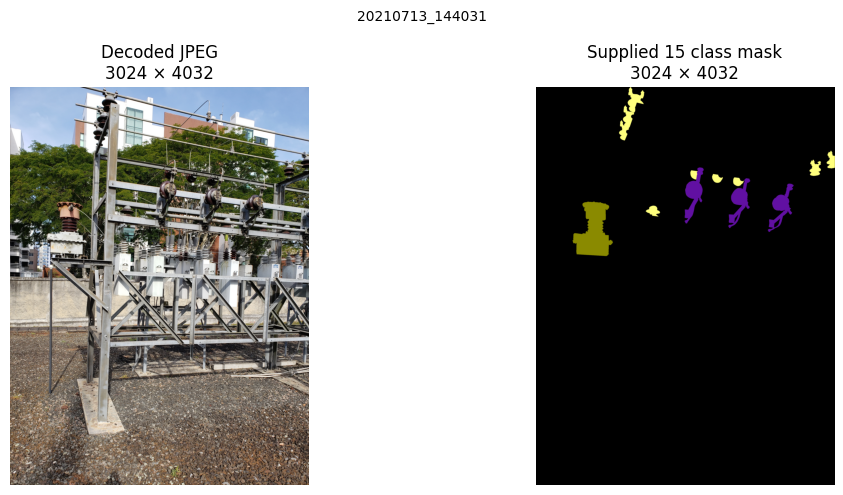

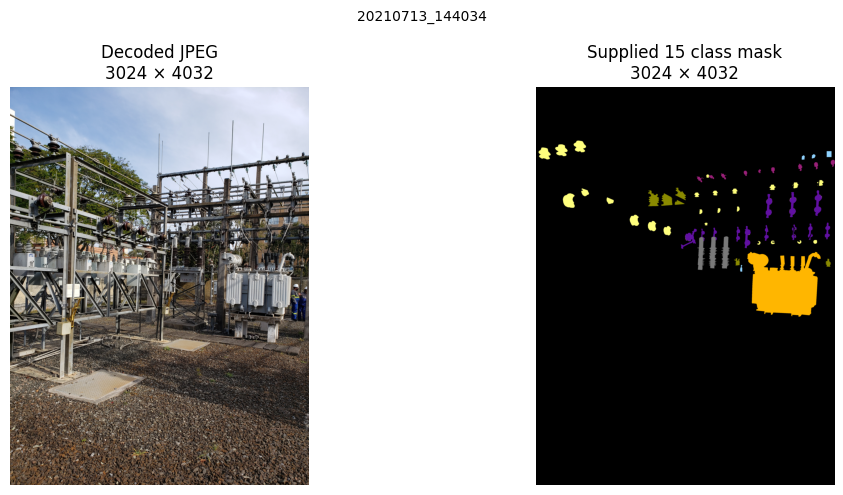

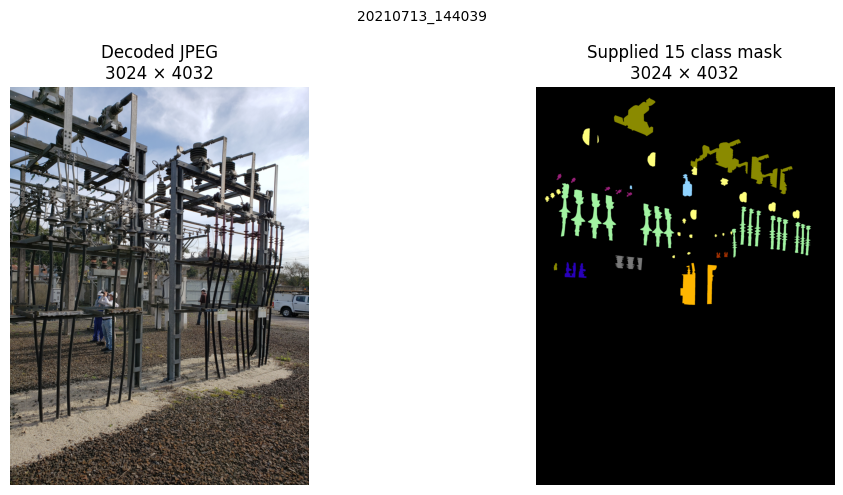


 EDA Quality Summary
Original images inspected: 1,660
Unreadable images: 0
Images with matching JSON dimensions: 1496
Images with mismatched JSON dimensions: 164
Mismatches consistent with EXIF rotation: 0
Images with at least one image/mask dimension mismatch: 164
Exact JSON to mask comparisons: 4978 / 4980
JSON to mask comparisons with differences: 2

Previously established annotation findings:
- 50,602 equipment polygons in the available JSON files
- 2,284 valid Background polygons
- 6 JSON files containing no shapes
- 44 polygons with minor out-of-bounds coordinates
- 103 fewer equipment polygons than published counts

No source files were modified.


In [13]:
from pathlib import Path
from collections import Counter
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ExifTags
try:
    dataset_root = Path(dataset_extraction_directory)
    image_directory = dataset_root / "images"
    mask_directories = {
        "15_masks": dataset_root / "15_masks",
        "14_masks": dataset_root / "14_masks",
        "porcelain_masks": dataset_root / "porcelain_masks"
    }
    mismatched_images = image_characteristics_df.loc[
        ~image_characteristics_df["dimensions_match"]
    ].copy()
    print("Image mask Alignment investigation")
    print(f"Images with JSON dimension mismatches: {len(mismatched_images)}")
    # Determine whether the JSON width and height are interchanged.
    mismatched_images["dimensions_swapped"] = (
        (mismatched_images["actual_width"] == mismatched_images["json_height"])
        &
        (mismatched_images["actual_height"] == mismatched_images["json_width"])
    )
    print("\n Dimension Mismatch Classification")
    print(
        mismatched_images["dimensions_swapped"]
        .map({True: "Width/height swapped", False: "Other mismatch"})
        .value_counts()
        .to_string()
    )
    # Inspect EXIF metadata without applying automatic orientation correction.
    orientation_tag = next(
        (
            tag_id
            for tag_id, tag_name in ExifTags.TAGS.items()
            if tag_name == "Orientation"
        ),
        274
    )
    orientation_records = []
    orientation_errors = []
    for row in mismatched_images.itertuples(index=False):
        image_path = image_directory / row.file_name
        try:
            with Image.open(image_path) as image:
                raw_dimensions = image.size
                orientation = image.getexif().get(orientation_tag, 1)
            orientation_records.append({
                "image_identifier": row.image_identifier,
                "exif_orientation": orientation,
                "raw_width": raw_dimensions[0],
                "raw_height": raw_dimensions[1],
                "raw_matches_json": (
                    raw_dimensions == (row.json_width, row.json_height)
                ),
                "raw_matches_opencv": (
                    raw_dimensions == (row.actual_width, row.actual_height)
                ),
                "opencv_matches_exif_rotation": (
                    orientation in {5, 6, 7, 8}
                    and raw_dimensions == (row.json_width, row.json_height)
                    and (row.actual_width, row.actual_height)
                    == (row.json_height, row.json_width)
                )
            })
        except Exception as error:
            orientation_errors.append({
                "image_identifier": row.image_identifier,
                "error": str(error)
            })
    orientation_df = pd.DataFrame(orientation_records)
    print("\n JPEG EXIF Orientation")
    if not orientation_df.empty:
        print(
            orientation_df["exif_orientation"]
            .value_counts(dropna=False)
            .sort_index()
            .to_string()
        )
        print(
            "\nRaw JPEG dimensions match JSON:",
            int(orientation_df["raw_matches_json"].sum())
        )
        print(
            "Raw JPEG dimensions match OpenCV:",
            int(orientation_df["raw_matches_opencv"].sum())
        )
        print(
            "Cases consistent with EXIF driven rotation:",
            int(orientation_df["opencv_matches_exif_rotation"].sum())
        )
    print(f"EXIF inspection errors: {len(orientation_errors)}")
    # Check all supplied masks, including those belonging to matching images.
    mask_alignment_records = []
    mask_alignment_errors = []
    for row in image_characteristics_df.itertuples(index=False):
        for mask_type, mask_directory in mask_directories.items():
            mask_path = mask_directory / f"{row.image_identifier}.png"
            try:
                mask = cv2.imread(
                    str(mask_path),
                    cv2.IMREAD_UNCHANGED
                )
                if mask is None:
                    raise ValueError("Mask could not be decoded.")
                mask_height, mask_width = mask.shape[:2]
                mask_alignment_records.append({
                    "image_identifier": row.image_identifier,
                    "mask_type": mask_type,
                    "image_dimensions_match_json": row.dimensions_match,
                    "mask_matches_image": (
                        mask_width == row.actual_width
                        and mask_height == row.actual_height
                    ),
                    "mask_matches_json": (
                        mask_width == row.json_width
                        and mask_height == row.json_height
                    ),
                    "mask_width": mask_width,
                    "mask_height": mask_height
                })
            except Exception as error:
                mask_alignment_errors.append({
                    "image_identifier": row.image_identifier,
                    "mask_type": mask_type,
                    "error": str(error)
                })
    mask_alignment_df = pd.DataFrame(mask_alignment_records)
    print("\n Mask Dimension Alignment")
    if not mask_alignment_df.empty:
        alignment_summary = mask_alignment_df.groupby("mask_type").agg(
            masks_checked=("image_identifier", "count"),
            match_actual_image=("mask_matches_image", "sum"),
            match_json_metadata=("mask_matches_json", "sum")
        )
        print(alignment_summary.to_string())
        affected_alignment = mask_alignment_df.loc[
            ~mask_alignment_df["mask_matches_image"]
        ]
        print(
            "\nUnique images with mask/image dimension mismatch:",
            affected_alignment["image_identifier"].nunique()
        )
    print(f"Mask inspection errors: {len(mask_alignment_errors)}")
    # Display a small sample without rotating or resizing either image.
    print("\n Visual Inspection — Representative Mismatches")
    sample_rows = mismatched_images.head(3)
    for row in sample_rows.itertuples(index=False):
        image_path = image_directory / row.file_name
        mask_path = (
            mask_directories["15_masks"]
            / f"{row.image_identifier}.png"
        )
        image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        mask = cv2.imread(str(mask_path), cv2.IMREAD_COLOR)
        if image is None or mask is None:
            print(f"Unable to display: {row.image_identifier}")
            continue
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask_rgb = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        axes[0].imshow(image_rgb)
        axes[0].set_title(
            f"Decoded JPEG\n{image.shape[1]} × {image.shape[0]}"
        )
        axes[0].axis("off")
        axes[1].imshow(mask_rgb)
        axes[1].set_title(
            f"Supplied 15 class mask\n{mask.shape[1]} × {mask.shape[0]}"
        )
        axes[1].axis("off")
        fig.suptitle(row.image_identifier, fontsize=10)
        plt.tight_layout()
        plt.show()
        plt.close(fig)
    # Summarize what has been established without treating
    # unresolved discrepancies as automatically corrected.
    print("\n EDA Quality Summary")
    print(f"Original images inspected: {len(image_characteristics_df):,}")
    print(f"Unreadable images: {len(image_integrity_errors_df):,}")
    print(
        "Images with matching JSON dimensions:",
        int(image_characteristics_df["dimensions_match"].sum())
    )
    print(f"Images with mismatched JSON dimensions: {len(mismatched_images)}")
    if not orientation_df.empty:
        print(
            "Mismatches consistent with EXIF rotation:",
            int(orientation_df["opencv_matches_exif_rotation"].sum())
        )
    if not mask_alignment_df.empty:
        print(
            "Images with at least one image/mask dimension mismatch:",
            int(
                mask_alignment_df.loc[
                    ~mask_alignment_df["mask_matches_image"],
                    "image_identifier"
                ].nunique()
            )
        )
    print(
        "Exact JSON to mask comparisons:",
        int(full_mask_validation_df["exact_match"].sum()),
        "/",
        len(full_mask_validation_df)
    )
    print(
        "JSON to mask comparisons with differences:",
        int((~full_mask_validation_df["exact_match"]).sum())
    )
    print("\nPreviously established annotation findings:")
    print("- 50,602 equipment polygons in the available JSON files")
    print("- 2,284 valid Background polygons")
    print("- 6 JSON files containing no shapes")
    print("- 44 polygons with minor out-of-bounds coordinates")
    print("- 103 fewer equipment polygons than published counts")
    print("\nNo source files were modified.")
except Exception as error:
    print(f"This cell could not be completed: {error}")


### Verification of JPEG Orientation and Segmentation Mask Alignment

The previous analysis identified 164 images whose decoded dimensions differed from the JSON annotation metadata. Visual inspection showed that the affected images and masks appeared to share a similar orientation, although their pixel level alignment had not been established.

This experiment examines a representative affected image using different OpenCV decoding options. The dimensions are compared with the corresponding JSON metadata and supplied segmentation mask.

An overlay is generated when image and mask dimensions match, allowing the spatial correspondence between annotated regions and visible equipment to be assessed.

No images, masks, or annotations are modified. The purpose is to identify the appropriate image loading procedure before segmentation modelling.

JPEG Orientation and Mask Alignment
Image identifier: 20210713_144031
Raw JPEG dimensions (Pillow): (4032, 3024)
EXIF orientation tag: 6
JSON dimensions: (3024, 4032)
Supplied mask dimensions: (3024, 4032)
OpenCV default dimensions: (3024, 4032)
OpenCV ignore-EXIF dimensions: (4032, 3024)

Dimension Comparisons
Default OpenCV matches mask: True
Ignore-EXIF OpenCV matches mask: False
Raw JPEG matches JSON: False


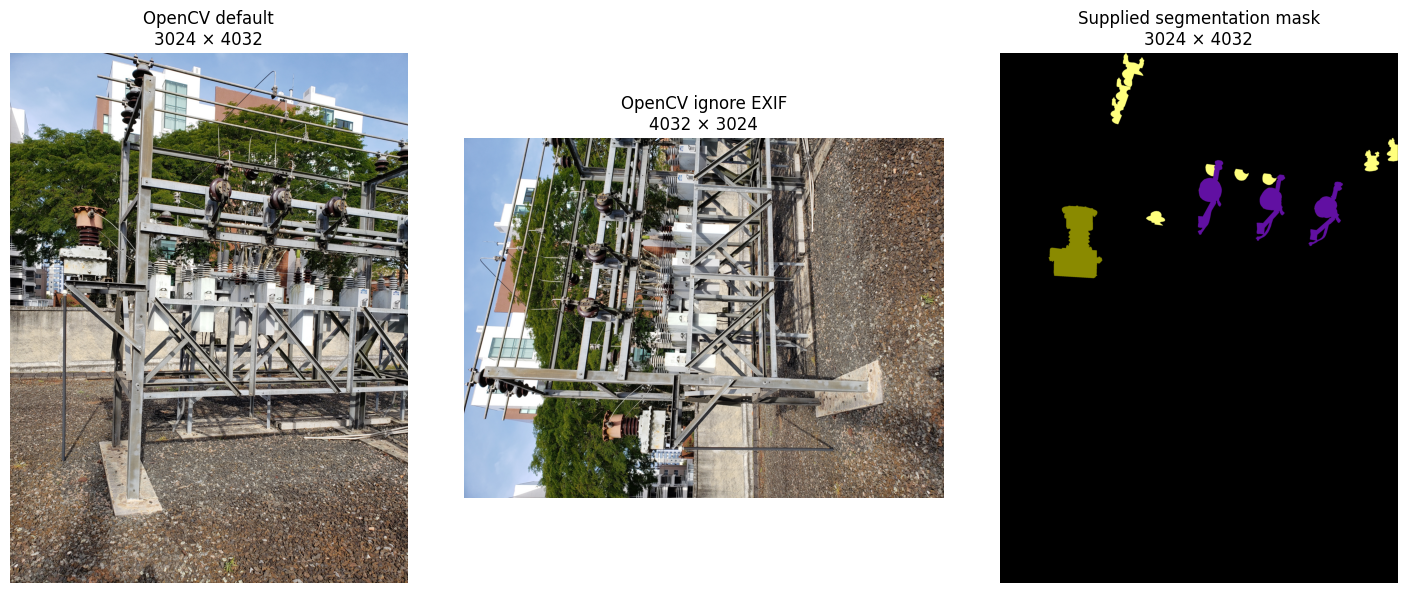

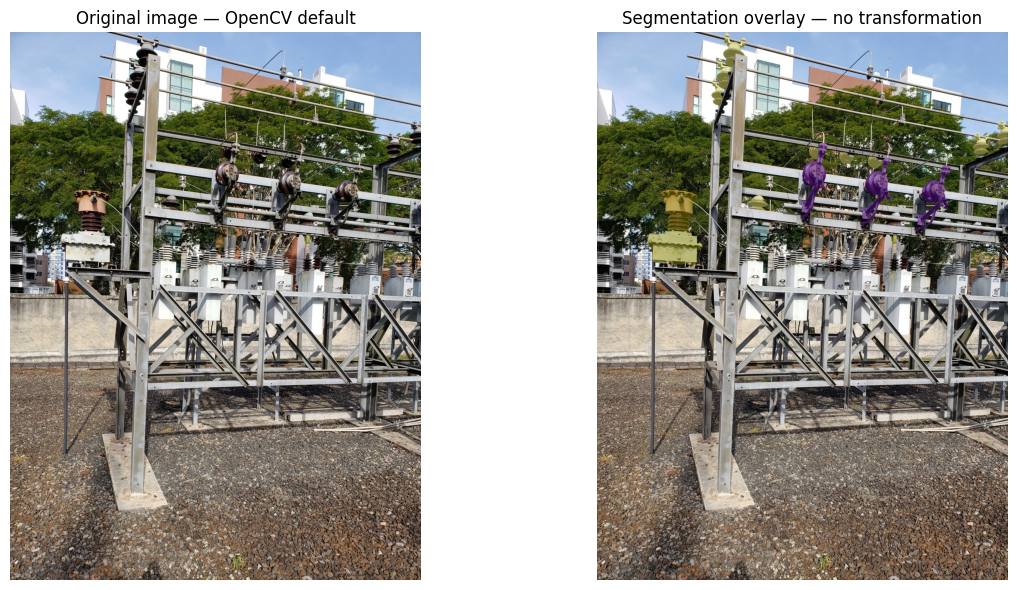


Overlay skipped for OpenCV ignore EXIF: image and mask dimensions differ.

Verification completed. Original files remain unchanged.


In [14]:
from pathlib import Path
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ExifTags
try:
    dataset_root = Path(dataset_extraction_directory)
    image_identifier = "20210713_144031"
    image_matches = [
        path
        for path in (dataset_root / "images").iterdir()
        if path.is_file()
        and path.stem == image_identifier
        and path.suffix.lower() in {".jpg", ".jpeg"}
    ]
    if len(image_matches) != 1:
        raise ValueError(
            f"Expected one JPEG for {image_identifier}, "
            f"found {len(image_matches)}."
        )
    image_path = image_matches[0]
    annotation_path = (
        dataset_root / "labels_json" / f"{image_identifier}.json"
    )
    mask_path = (
        dataset_root / "15_masks" / f"{image_identifier}.png"
    )
    with annotation_path.open("r", encoding="utf-8") as file:
        annotation = json.load(file)
    # Compare OpenCV's default behavior with explicit EXIF avoidance.
    image_default = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )
    image_ignore_exif = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION
    )
    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_COLOR
    )
    if any(item is None for item in [
        image_default, image_ignore_exif, mask
    ]):
        raise ValueError("One or more image files could not be decoded.")
    with Image.open(image_path) as pil_image:
        raw_dimensions = pil_image.size
        exif_orientation = pil_image.getexif().get(274, 1)
    def dimensions(image):
        return (image.shape[1], image.shape[0])
    json_dimensions = (
        annotation["imageWidth"],
        annotation["imageHeight"]
    )
    print("JPEG Orientation and Mask Alignment")
    print(f"Image identifier: {image_identifier}")
    print(f"Raw JPEG dimensions (Pillow): {raw_dimensions}")
    print(f"EXIF orientation tag: {exif_orientation}")
    print(f"JSON dimensions: {json_dimensions}")
    print(f"Supplied mask dimensions: {dimensions(mask)}")
    print(f"OpenCV default dimensions: {dimensions(image_default)}")
    print(f"OpenCV ignore-EXIF dimensions: {dimensions(image_ignore_exif)}")
    print("\nDimension Comparisons")
    print(
        "Default OpenCV matches mask:",
        dimensions(image_default) == dimensions(mask)
    )
    print(
        "Ignore-EXIF OpenCV matches mask:",
        dimensions(image_ignore_exif) == dimensions(mask)
    )
    print(
        "Raw JPEG matches JSON:",
        raw_dimensions == json_dimensions
    )
    # Display the two decoding methods side by side.
    fig, axes = plt.subplots(1, 3, figsize=(15, 6))
    display_items = [
        (image_default, "OpenCV default"),
        (image_ignore_exif, "OpenCV ignore EXIF"),
        (mask, "Supplied segmentation mask")
    ]
    for axis, (image, title) in zip(axes, display_items):
        axis.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        axis.set_title(
            f"{title}\n{image.shape[1]} × {image.shape[0]}"
        )
        axis.axis("off")
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    # Overlay only the decoding variant whose dimensions match the mask.
    matching_variants = [
        ("OpenCV default", image_default),
        ("OpenCV ignore EXIF", image_ignore_exif)
    ]
    for variant_name, image in matching_variants:
        if image.shape[:2] != mask.shape[:2]:
            print(
                f"\nOverlay skipped for {variant_name}: "
                "image and mask dimensions differ."
            )
            continue
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask_rgb = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)
        # Keep the original background visible.
        foreground_pixels = np.any(mask_rgb != 0, axis=2)
        overlay = image_rgb.copy()
        overlay[foreground_pixels] = (
            0.55 * image_rgb[foreground_pixels].astype(np.float32)
            + 0.45 * mask_rgb[foreground_pixels].astype(np.float32)
        ).astype(np.uint8)
        fig, axes = plt.subplots(1, 2, figsize=(13, 6))
        axes[0].imshow(image_rgb)
        axes[0].set_title(f"Original image — {variant_name}")
        axes[0].axis("off")
        axes[1].imshow(overlay)
        axes[1].set_title("Segmentation overlay — no transformation")
        axes[1].axis("off")
        plt.tight_layout()
        plt.show()
        plt.close(fig)
    print("\nVerification completed. Original files remain unchanged.")
except Exception as error:
    print(f"This verification failed: {error}")


### Findings -> JPEG Orientation and Mask Alignment

The orientation investigation examined a representative image previously identified as having inconsistent dimensions.

The JPEG's raw dimensions were 4032 x 3024 pixels, while the corresponding JSON annotation and supplied segmentation mask both used dimensions of 3024 x 4032 pixels.

The JPEG contained EXIF orientation value 6, indicating that a 90 degree clockwise rotation should be applied for correct display.

OpenCV's default color decoding produced the orientation corrected dimensions of 3024 x 4032 pixels, matching the JSON annotation and segmentation mask. Decoding with EXIF orientation explicitly ignored instead produced the raw dimensions of 4032 x 3024 pixels.

Visual inspection of the image mask overlay showed that the annotated equipment regions aligned with the corresponding visible structures.

These results demonstrate that the dimension discrepancy for the examined image is attributable to JPEG orientation handling rather than an incorrectly sized segmentation mask.

The finding has an important preprocessing implication: images should be decoded using a method that respects their EXIF orientation metadata to maintain spatial consistency with the supplied masks.

Although this explanation has been verified for the representative image, the remaining affected images require a batch dimension check before the finding can be generalized to all 164 cases.

No original files were modified.

In [15]:
from pathlib import Path
import cv2
import pandas as pd
from PIL import Image
try:
    dataset_root = Path(dataset_extraction_directory)
    image_directory = dataset_root / "images"
    mask_directories = {
        "15_masks": dataset_root / "15_masks",
        "14_masks": dataset_root / "14_masks",
        "porcelain_masks": dataset_root / "porcelain_masks"
    }
    # Revisit only images flagged by the earlier dimension check.
    affected_images = image_characteristics_df.loc[
        ~image_characteristics_df["dimensions_match"]
    ].copy()
    verification_records = []
    verification_errors = []
    for row in affected_images.itertuples(index=False):
        try:
            image_path = image_directory / row.file_name
            # Default color decoding applies supported EXIF orientation.
            image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
            if image is None:
                raise ValueError("Unable to decode JPEG.")
            image_height, image_width = image.shape[:2]
            with Image.open(image_path) as pil_image:
                exif_orientation = pil_image.getexif().get(274, 1)
            json_match = (
                image_width == row.json_width
                and image_height == row.json_height
            )
            mask_matches = {}
            for mask_type, mask_directory in mask_directories.items():
                mask_path = (
                    mask_directory / f"{row.image_identifier}.png"
                )
                mask = cv2.imread(
                    str(mask_path),
                    cv2.IMREAD_UNCHANGED
                )
                if mask is None:
                    raise ValueError(
                        f"Unable to decode {mask_type} mask."
                    )
                mask_matches[mask_type] = (
                    mask.shape[:2] == image.shape[:2]
                )
            verification_records.append({
                "image_identifier": row.image_identifier,
                "exif_orientation": exif_orientation,
                "decoded_width": image_width,
                "decoded_height": image_height,
                "matches_json": json_match,
                "matches_15_masks": mask_matches["15_masks"],
                "matches_14_masks": mask_matches["14_masks"],
                "matches_porcelain_masks": mask_matches["porcelain_masks"]
            })
        except Exception as error:
            verification_errors.append({
                "image_identifier": row.image_identifier,
                "error": str(error)
            })
    orientation_verification_df = pd.DataFrame(verification_records)
    orientation_verification_errors_df = pd.DataFrame(verification_errors)
    print("EXIF Aware Image Mask Alignment Verification")
    print(f"Affected images: {len(affected_images)}")
    print(f"Successfully checked: {len(orientation_verification_df)}")
    print(f"Processing errors: {len(orientation_verification_errors_df)}")
    if not orientation_verification_df.empty:
        print("\nEXIF Orientation Distribution")
        print(
            orientation_verification_df["exif_orientation"]
            .value_counts()
            .sort_index()
            .to_string()
        )
        print("\nDimension Alignment Summary")
        alignment_columns = [
            "matches_json",
            "matches_15_masks",
            "matches_14_masks",
            "matches_porcelain_masks"
        ]
        for column in alignment_columns:
            matching_count = int(
                orientation_verification_df[column].sum()
            )
            print(
                f"{column}: {matching_count} / "
                f"{len(orientation_verification_df)}"
            )
        unresolved = orientation_verification_df.loc[
            ~orientation_verification_df[alignment_columns].all(axis=1)
        ]
        print(f"\nImages with unresolved dimension alignment: {len(unresolved)}")
        if not unresolved.empty:
            print(unresolved.head(20).to_string(index=False))
    if not orientation_verification_errors_df.empty:
        print("\nProcessing Errors")
        print(
            orientation_verification_errors_df
            .head(20)
            .to_string(index=False)
        )
    print("\nVerification completed. Original files remain unchanged.")
except Exception as error:
    print(f"This cell could not be completed: {error}")


EXIF Aware Image Mask Alignment Verification
Affected images: 164
Successfully checked: 164
Processing errors: 0

EXIF Orientation Distribution
exif_orientation
6    159
8      5

Dimension Alignment Summary
matches_json: 164 / 164
matches_15_masks: 164 / 164
matches_14_masks: 164 / 164
matches_porcelain_masks: 164 / 164

Images with unresolved dimension alignment: 0

Verification completed. Original files remain unchanged.


###Findings -> Resolution of Image Mask Dimension Mismatches

The EXIF aware validation successfully examined all 164 images previously identified as having dimension mismatches.

Of these images, 159 contained EXIF orientation value 6, while five contained orientation value 8. Both values indicate that orientation correction is required when decoding the original JPEG files.

Using OpenCV's default color decoding, all 164 images matched the dimensions recorded in their JSON annotations and the corresponding 15 class, 14 class, and porcelain only segmentation masks.

No processing errors or unresolved dimension mismatches were observed.

Combined with the representative image mask overlay examined previously, these results establish that the dimension discrepancies were caused by JPEG orientation handling rather than inconsistent annotation dimensions.

For subsequent segmentation experiments, JPEG images must be loaded using an EXIF aware decoding method. The supplied masks can retain their existing orientation.

The original dataset files remain unchanged.

### Final Exploratory Analysis -> Class Distribution and Dataset Redundancy

This stage consolidates the remaining exploratory analyses needed to understand the dataset before preprocessing and model development.

The analysis examines the distribution of segmentation classes at the pixel level, the number of images containing each equipment class, the validity of the mask color palette, and the presence of exact duplicate images.

Pixel level class frequencies are calculated from the supplied 15 class segmentation masks using the original authors' color definitions. These frequencies are compared with image level class occurrence to distinguish frequently annotated objects from classes occupying large image regions.

The analysis also checks whether all mask pixels belong to the documented color palette and whether the expected class restrictions are respected in the 14 class and porcelain only masks.

Exact duplicate detection is performed using SHA 256 hashes of the original image files. This identifies byte identical files but does not detect visually similar images or repeated photographs saved with different compression settings.

The findings will inform later decisions about class imbalance, dataset splitting, and segmentation evaluation. No images, masks, or annotations are modified.

FINAL CONSOLIDATED EDA:
Images discovered: 1,660
Processed 200 / 1,660 images
Processed 400 / 1,660 images
Processed 600 / 1,660 images
Processed 800 / 1,660 images
Processed 1,000 / 1,660 images
Processed 1,200 / 1,660 images
Processed 1,400 / 1,660 images
Processed 1,600 / 1,660 images
Processed 1,660 / 1,660 images

 Pixel level class distribution
 class_index                      class_name  pixel_count  pixel_percentage  images_containing_class  image_occurrence_percentage
           0                      Background   5783826983           91.7131                     1660                     100.0000
          12               Power transformer    142229554            2.2553                      406                      24.4578
          11                        Recloser    112070594            1.7771                      861                      51.8675
           2  Closed blade disconnect switch     70330989            1.1152                     1066                      64.21

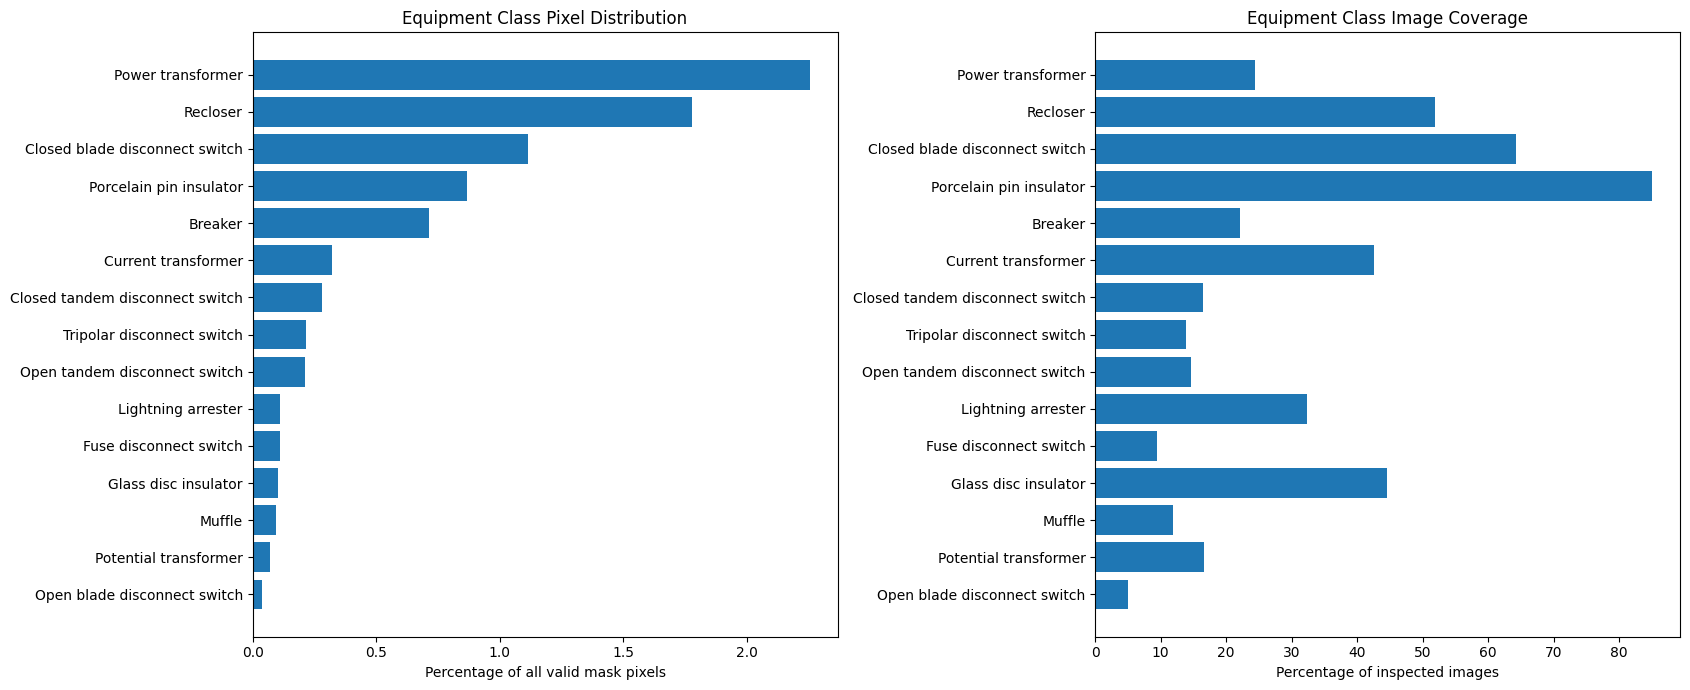


Final EDA Check Complete!!!!
All original dataset files remain unchanged.


In [16]:
from pathlib import Path
from collections import Counter, defaultdict
import hashlib
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    dataset_root = Path(dataset_extraction_directory)
    image_directory = dataset_root / "images"
    mask_directories = {
        "15_masks": dataset_root / "15_masks",
        "14_masks": dataset_root / "14_masks",
        "porcelain_masks": dataset_root / "porcelain_masks"
    }
    # These colors are defined in the original json2png.py script.
    # They are specified in the order passed to cv2.fillPoly.
    author_palette = [
        (0, 0, 0),
        (162, 0, 255),
        (97, 16, 162),
        (81, 162, 0),
        (48, 97, 165),
        (121, 121, 121),
        (255, 97, 178),
        (154, 32, 121),
        (255, 255, 125),
        (162, 243, 162),
        (143, 211, 255),
        (40, 0, 186),
        (255, 182, 0),
        (138, 138, 0),
        (162, 48, 0),
        (162, 0, 96)
    ]
    if len(dataset_class_names) != len(author_palette):
        raise ValueError("Class names and palette lengths do not match.")
    if dataset_class_names[0] != "Background":
        raise ValueError("Unexpected Background class index.")
    if dataset_class_names[8] != "Porcelain pin insulator":
        raise ValueError("Unexpected porcelain class index.")
    # The authors swap channels before saving PNG files.
    # cv2.imread reads those PNG files back in BGR order.
    # Therefore, the observed BGR colors are the reversed palette tuples.
    expected_bgr_palette = np.array(
        [color[::-1] for color in author_palette],
        dtype=np.uint8
    )
    # Encode each BGR triplet as one integer for efficient pixel counting.
    def encode_colors(color_array):
        values = color_array.astype(np.uint32)
        return (
            (values[..., 0] << 16)
            | (values[..., 1] << 8)
            | values[..., 2]
        )
    encoded_palette = encode_colors(expected_bgr_palette)
    if len(np.unique(encoded_palette)) != len(encoded_palette):
        raise ValueError("The documented palette contains duplicate colors.")
    color_to_class = {
        int(color_code): class_index
        for class_index, color_code in enumerate(encoded_palette)
    }
    image_files = sorted(
        path for path in image_directory.iterdir()
        if path.is_file()
        and path.suffix.lower() in {".jpg", ".jpeg"}
    )
    if not image_files:
        raise ValueError("No JPEG images were found.")
    pixel_counts = np.zeros(len(dataset_class_names), dtype=np.int64)
    image_occurrences = np.zeros(len(dataset_class_names), dtype=np.int64)
    mask_palette_issues = []
    mask_processing_errors = []
    image_class_records = []
    # Track violations of the intended contents of the separate masks.
    mask_variant_issues = []
    print("FINAL CONSOLIDATED EDA:")
    print(f"Images discovered: {len(image_files):,}")
    for image_number, image_path in enumerate(image_files, start=1):
        image_identifier = image_path.stem
        try:
            mask_class_counts = {}
            for mask_type, mask_directory in mask_directories.items():
                mask_path = mask_directory / f"{image_identifier}.png"
                mask = cv2.imread(
                    str(mask_path),
                    cv2.IMREAD_UNCHANGED
                )
                if mask is None:
                    raise ValueError(
                        f"Unable to read {mask_type} mask."
                    )
                if mask.ndim != 3 or mask.shape[2] != 3:
                    raise ValueError(
                        f"Unexpected {mask_type} mask shape: {mask.shape}"
                    )
                encoded_pixels = encode_colors(mask)
                unique_colors, color_frequencies = np.unique(
                    encoded_pixels,
                    return_counts=True
                )
                class_counts = np.zeros(
                    len(dataset_class_names),
                    dtype=np.int64
                )
                for color_code, frequency in zip(
                    unique_colors, color_frequencies
                ):
                    color_code = int(color_code)
                    frequency = int(frequency)
                    if color_code not in color_to_class:
                        mask_palette_issues.append({
                            "image_identifier": image_identifier,
                            "mask_type": mask_type,
                            "unknown_color_code": color_code,
                            "pixel_count": frequency
                        })
                        continue
                    class_index = color_to_class[color_code]
                    class_counts[class_index] += frequency
                    # 14_masks should not contain porcelain class 8.
                    if mask_type == "14_masks" and class_index == 8:
                        mask_variant_issues.append({
                            "image_identifier": image_identifier,
                            "mask_type": mask_type,
                            "unexpected_class": dataset_class_names[class_index]
                        })
                    # Porcelain masks should contain only class 0 and class 8.
                    if (
                        mask_type == "porcelain_masks"
                        and class_index not in {0, 8}
                    ):
                        mask_variant_issues.append({
                            "image_identifier": image_identifier,
                            "mask_type": mask_type,
                            "unexpected_class": dataset_class_names[class_index]
                        })
                mask_class_counts[mask_type] = class_counts
            # Count pixels and class occurrences from the full 15_class mask.
            full_mask_counts = mask_class_counts["15_masks"]
            pixel_counts += full_mask_counts
            image_occurrences += (full_mask_counts > 0).astype(np.int64)
            image_class_records.append({
                "image_identifier": image_identifier,
                "equipment_classes_present": int(
                    np.count_nonzero(full_mask_counts[1:])
                ),
                "foreground_pixels": int(full_mask_counts[1:].sum()),
                "background_pixels": int(full_mask_counts[0]),
                "total_pixels": int(full_mask_counts.sum()),
                "foreground_percentage": (
                    100 * full_mask_counts[1:].sum()
                    / full_mask_counts.sum()
                )
            })
        except Exception as error:
            mask_processing_errors.append({
                "image_identifier": image_identifier,
                "error": str(error)
            })
        if image_number % 200 == 0 or image_number == len(image_files):
            print(
                f"Processed {image_number:,} / {len(image_files):,} images"
            )
    # Summarize class frequencies using successfully inspected full masks.
    total_valid_pixels = int(pixel_counts.sum())
    successfully_inspected = len(image_class_records)
    if total_valid_pixels == 0:
        raise ValueError("No valid mask pixels were counted.")
    pixel_class_distribution_df = pd.DataFrame({
        "class_index": range(len(dataset_class_names)),
        "class_name": dataset_class_names,
        "pixel_count": pixel_counts,
        "pixel_percentage": 100 * pixel_counts / total_valid_pixels,
        "images_containing_class": image_occurrences,
        "image_occurrence_percentage": (
            100 * image_occurrences / successfully_inspected
        )
    })
    image_class_coverage_df = pd.DataFrame(image_class_records)
    mask_palette_issues_df = pd.DataFrame(mask_palette_issues)
    mask_variant_issues_df = pd.DataFrame(mask_variant_issues)
    mask_processing_errors_df = pd.DataFrame(mask_processing_errors)
    print("\n Pixel level class distribution")
    print(
        pixel_class_distribution_df
        .sort_values("pixel_count", ascending=False)
        .round(4)
        .to_string(index=False)
    )
    print("\n Image level class coverage")
    print(
        image_class_coverage_df[
            [
                "equipment_classes_present",
                "foreground_percentage"
            ]
        ].describe().round(3).to_string()
    )
    print("\nImages with no foreground equipment pixels:")
    print(
        int(
            (image_class_coverage_df["foreground_pixels"] == 0).sum()
        )
    )
    print("\n Mask palette validation")
    print(f"Unknown palette color records: {len(mask_palette_issues_df)}")
    print(f"Mask variant violations: {len(mask_variant_issues_df)}")
    print(f"Mask processing errors: {len(mask_processing_errors_df)}")
    if not mask_palette_issues_df.empty:
        print("\nFirst 10 unknown color records:")
        print(mask_palette_issues_df.head(10).to_string(index=False))
    if not mask_variant_issues_df.empty:
        print("\nFirst 10 mask variant violations:")
        print(mask_variant_issues_df.head(10).to_string(index=False))
    if not mask_processing_errors_df.empty:
        print("\nFirst 10 processing errors:")
        print(mask_processing_errors_df.head(10).to_string(index=False))
    # Hash the original JPEG bytes to identify exact duplicate files.
    print("\n Exact Duplicate Image Detection")
    image_hash_groups = defaultdict(list)
    hashing_errors = []
    for image_path in image_files:
        try:
            file_hash = hashlib.sha256()
            with image_path.open("rb") as image_file:
                for chunk in iter(
                    lambda: image_file.read(1024 * 1024),
                    b""
                ):
                    file_hash.update(chunk)
            image_hash_groups[file_hash.hexdigest()].append(
                image_path.name
            )
        except Exception as error:
            hashing_errors.append({
                "file_name": image_path.name,
                "error": str(error)
            })
    exact_duplicate_groups = {
        digest: filenames
        for digest, filenames in image_hash_groups.items()
        if len(filenames) > 1
    }
    exact_duplicate_image_count = sum(
        len(filenames) - 1
        for filenames in exact_duplicate_groups.values()
    )
    print(f"Images successfully hashed:{sum(map(len, image_hash_groups.values()))}")
    print(f"Unique SHA 256 hashes:{len(image_hash_groups)}")
    print(f"Exact duplicate groups:{len(exact_duplicate_groups)}")
    print(f"Additional duplicate files:{exact_duplicate_image_count}")
    print(f"Hashing errors:{len(hashing_errors)}")
    for group_number, filenames in enumerate(
        list(exact_duplicate_groups.values())[:10],
        start=1
    ):
        print(f"\nDuplicate group {group_number}:")
        for filename in filenames:
            print(f"  {filename}")
    # Keep the full duplicate information for later split design.
    exact_duplicate_groups_df = pd.DataFrame([
        {
            "sha256": digest,
            "file_name": filename,
            "group_size": len(filenames)
        }
        for digest, filenames in exact_duplicate_groups.items()
        for filename in filenames
    ])
    print("\n Class Distribution Visualization")
    equipment_distribution = pixel_class_distribution_df.loc[
        pixel_class_distribution_df["class_index"] != 0
    ].sort_values("pixel_percentage")
    fig, axes = plt.subplots(1, 2, figsize=(17, 7))
    axes[0].barh(
        equipment_distribution["class_name"],
        equipment_distribution["pixel_percentage"]
    )
    axes[0].set_xlabel("Percentage of all valid mask pixels")
    axes[0].set_title("Equipment Class Pixel Distribution")
    axes[1].barh(
        equipment_distribution["class_name"],
        equipment_distribution["image_occurrence_percentage"]
    )
    axes[1].set_xlabel("Percentage of inspected images")
    axes[1].set_title("Equipment Class Image Coverage")
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    print("\nFinal EDA Check Complete!!!!")
    print("All original dataset files remain unchanged.")
except Exception as error:
    print(f"This cell could not be completed: {error}")


### Final EDA Findings and Implications for Model Development

The exploratory data analysis examined 1,660 electrical substation images, their JSON polygon annotations, and three corresponding segmentation mask variants.

**Dataset integrity and annotation consistency**

All 1,660 images were readable. The dataset contains 50,602 equipment polygons across 15 equipment classes, together with 2,284 explicitly annotated Background polygons.

The JSON to mask reproducibility assessment produced exact matches for 4,978 of 4,980 comparisons. The remaining two comparisons differed by 14 pixels each and belonged to the same image.

All 164 previously identified image mask dimension mismatches were resolved through EXIF,aware image decoding. No unresolved dimension mismatches remained.

**Segmentation mask validity**

The complete mask validation detected no unknown palette colors, mask variant violations, or processing errors.

All three supplied mask variants followed the documented class color encoding and class separation rules.

**Pixel level class imbalance**

Background accounts for 91.7131% of all segmentation mask pixels, while the combined equipment classes occupy approximately 8.2869%.

Power transformers have the largest equipment pixel share at 2.2553%, followed by reclosers at 1.7771% and closed blade disconnect switches at 1.1152%.

Open blade disconnect switches have the smallest pixel share at 0.0361%, followed by potential transformers at 0.0692%.

The imbalance indicates that overall pixel accuracy alone would be insufficient for evaluating segmentation quality. Per class metrics will be necessary, particularly for equipment categories with limited pixel coverage.

**Image level class distribution**

Images contain an average of 4.55 equipment classes, with a median of four and a maximum of 14.

Porcelain pin insulators appear in 1,412 images, representing 85.06% of the dataset. Closed blade disconnect switches appear in 1,066 images, while reclosers appear in 861 images.

Open blade disconnect switches appear in only 84 images, representing 5.06% of the dataset.

Six images contain no foreground equipment pixels in their supplied 15 class masks.

These differences in class occurrence should be considered when designing training, validation, and test partitions.

**Duplicate image analysis**

SHA 256 hashing identified 1,659 unique image file hashes among the 1,660 images.

One pair of byte identical images was detected: `1PANO0001.JPG` and `PANO0001d.JPG`.

This pair should be handled together during dataset splitting to prevent exact duplicate leakage between training and evaluation partitions.

The hashing analysis does not exclude visually similar images, repeated camera viewpoints, or near duplicate frames.

**Overall conclusion**

The dataset has passed the structural integrity, annotation reproducibility, mask palette, and image orientation checks, with a small number of documented discrepancies.

The principal challenges for subsequent model development are severe foreground background imbalance, unequal equipment class representation, variation in image resolution, and the possibility of correlated or near duplicate images.

These findings provide a data driven foundation for selecting segmentation architectures, preprocessing procedures, evaluation metrics, and dataset splitting strategies.

No original dataset files were modified during the exploratory analysis.